# UNSW-NB15 — Multiclass Network Intrusion Detection

Multiclass version of the binary notebook: instead of *Normal vs Attack*, the models predict **Normal + 9 attack categories**
(`Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Reconnaissance, Shellcode, Worms`) from the `attack_cat` column.

**Pipeline**
Import → Load → Verify → Overview → Data quality → EDA → Target → X/y → Data types → Encode → Split → Scale → Imbalance → Feature selection → Baselines → XGBoost/LightGBM → Tuning → Feature importance → SHAP → Evaluation → Final test → Compare → Select → Save → Conclusion

**What changes versus the binary notebook**
- Target is `attack_cat` (label-encoded), `label` is only used for a sanity check.
- Metrics are macro-averaged (each class counts equally) — plain accuracy would hide failures on rare classes like `Worms`.
- Tuning is scored with `f1_macro`; XGBoost uses `multi:softprob`, LightGBM uses `multiclass`.
- SMOTE is capped (see `SMOTE_TARGET`) instead of oversampling every class to the size of `Normal`.
- SMOTE is applied *inside* the cross-validation folds during tuning, so validation folds never contain synthetic copies of training points.
- SHAP is per-class.
- Test-set results are reported but never used to pick the model — selection uses the validation split only.

## Step 0 — Import Libraries

In [1]:
# Run once if a package is missing:
# !pip install pyarrow imbalanced-learn xgboost lightgbm shap seaborn scikit-learn joblib

In [2]:
import json
import warnings
from collections import Counter
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

import joblib
import shap

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1 — Load UNSW-NB15 Training and Testing Data

In [3]:
DATA_DIR = Path(r"E:\BRM003-ML-Project\dataset folder\archive (1)")

train_path = DATA_DIR / "UNSW_NB15_training-set.parquet"
test_candidates = [
    DATA_DIR / "UNSW_NB15_test-set.parquet",
    DATA_DIR / "UNSW_NB15_testing-set.parquet",
    DATA_DIR / "UNSW_NB15_test-set.csv",
    DATA_DIR / "UNSW_NB15_testing-set.csv",
]
test_path = next((p for p in test_candidates if p.exists()), None)
if test_path is None:
    raise FileNotFoundError(f"No UNSW-NB15 test file found in {DATA_DIR}")

def read_any(path):
    return pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)

train_df = read_any(train_path)
test_df = read_any(test_path)

print("Train file:", train_path.name, train_df.shape)
print("Test file :", test_path.name, test_df.shape)

Train file: UNSW_NB15_training-set.parquet (175341, 36)
Test file : UNSW_NB15_testing-set.parquet (82332, 36)


## Step 2 — Combine / Verify Dataset Structure

The official train and test files are kept **separate** for modelling (the test file is the held-out set).
Here we only check they line up, make their dtypes consistent, and look at them side by side.

Categorical columns arrive as pandas `category` with *different category lists* in train and test (e.g. `state`),
so they are converted to plain strings — this also makes one-hot alignment in Step 9 straightforward.

In [4]:
train_cols, test_cols = set(train_df.columns), set(test_df.columns)
print("Columns only in train:", train_cols - test_cols)
print("Columns only in test :", test_cols - train_cols)
print("Column count — train:", train_df.shape[1], "| test:", test_df.shape[1])

Columns only in train: set()
Columns only in test : set()
Column count — train: 36 | test: 36


In [5]:
TARGET_COL, BINARY_COL, ID_COL = "attack_cat", "label", "id"

def harmonise(df):
    df = df.copy()
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].astype(str).str.strip()
    # tidy attack labels ('Backdoors' -> 'Backdoor', missing -> 'Normal')
    df[TARGET_COL] = df[TARGET_COL].replace({"Backdoors": "Backdoor", "nan": "Normal", "": "Normal", "-": "Normal"})
    return df

train_df = harmonise(train_df)
test_df = harmonise(test_df)

dtype_mismatch = {c: (str(train_df[c].dtype), str(test_df[c].dtype))
                  for c in train_cols & test_cols if str(train_df[c].dtype) != str(test_df[c].dtype)}
print("Dtype mismatches after harmonising:", dtype_mismatch or "None")
print("'id' column present:", ID_COL in train_df.columns)

Dtype mismatches after harmonising: None
'id' column present: False


In [6]:
# Side-by-side class distribution of the two official splits
dist = pd.concat(
    [train_df[TARGET_COL].value_counts().rename("train"), test_df[TARGET_COL].value_counts().rename("test")], axis=1
).fillna(0).astype(int)
dist["train_%"] = (dist["train"] / dist["train"].sum() * 100).round(2)
dist["test_%"] = (dist["test"] / dist["test"].sum() * 100).round(2)
print("Classes only in one split:", set(train_df[TARGET_COL]) ^ set(test_df[TARGET_COL]) or "None")
dist

Classes only in one split: None


,train,test,train_%,test_%
attack_cat,,,,
Normal,56000,37000,31.94,44.94
Generic,40000,18871,22.81,22.92
Exploits,33393,11132,19.04,13.52
Fuzzers,18184,6062,10.37,7.36
DoS,12264,4089,6.99,4.97
Reconnaissance,10491,3496,5.98,4.25
Analysis,2000,677,1.14,0.82
Backdoor,1746,583,1.00,0.71
Shellcode,1133,378,0.65,0.46


## Step 3 — Dataset Overview

In [7]:
print('train shape:', train_df.shape, '| test shape:', test_df.shape)

train shape: (175341, 36) | test shape: (82332, 36)


In [8]:
train_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.121478,tcp,-,FIN,6,4,258,172,74.087486,14158.942383,8495.365234,0,0,24.295601,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,1,0,0,0,0,Normal,0
1,0.649902,tcp,-,FIN,14,38,734,42014,78.473373,8395.112305,503571.312500,2,17,49.915001,15.432865,61.426933,1387.778320,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,1,1,0,0,0,0,Normal,0
2,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,1572.271851,60929.230469,1,6,231.875565,102.737206,17179.585938,11420.925781,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,1,1,0,0,0,0,Normal,0
3,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,2740.178955,3358.622070,1,3,152.876541,90.235725,259.080170,4991.784668,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,1,1,0,0,Normal,0
4,0.449454,tcp,-,FIN,10,6,534,268,33.373825,8561.499023,3987.059814,2,1,47.750332,75.659599,2415.837646,115.806999,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,2,1,0,0,0,0,Normal,0


In [9]:
test_df.head()

,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_src_dport_ltm,ct_dst_sport_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,-,INT,2,0,496,0,90909.09375,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,1,1,0,0,0,0,Normal,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.00000,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,1,1,0,0,0,0,Normal,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.00000,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,1,1,0,0,0,0,Normal,0
3,0.000006,udp,-,INT,2,0,900,0,166666.65625,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,2,1,0,0,0,0,Normal,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.00000,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,2,1,0,0,0,0,Normal,0


In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 36 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   dur                175341 non-null  float32
 1   proto              175341 non-null  str    
 2   service            175341 non-null  str    
 3   state              175341 non-null  str    
 4   spkts              175341 non-null  int16  
 5   dpkts              175341 non-null  int16  
 6   sbytes             175341 non-null  int32  
 7   dbytes             175341 non-null  int32  
 8   rate               175341 non-null  float32
 9   sload              175341 non-null  float32
 10  dload              175341 non-null  float32
 11  sloss              175341 non-null  int16  
 12  dloss              175341 non-null  int16  
 13  sinpkt             175341 non-null  float32
 14  dinpkt             175341 non-null  float32
 15  sjit               175341 non-null  float32
 16  djit         

In [11]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
dur,175341.0,1.359389e+00,6.480249e+00,0.0,0.000008,0.001582,6.680690e-01,5.999999e+01
spkts,175341.0,2.029866e+01,1.368876e+02,1.0,2.000000,2.000000,1.200000e+01,9.616000e+03
dpkts,175341.0,1.896959e+01,1.102583e+02,0.0,0.000000,2.000000,1.000000e+01,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000000,430.000000,1.418000e+03,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000000,164.000000,1.102000e+03,1.465555e+07
rate,175341.0,9.540618e+04,1.654010e+05,0.0,32.786140,3225.806641,1.250000e+05,1.000000e+06
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.338867,879674.750000,8.888889e+07,5.988000e+09
dload,175341.0,6.712056e+05,2.421312e+06,0.0,0.000000,1447.022705,2.784487e+04,2.242273e+07
sloss,175341.0,4.953000e+00,6.600506e+01,0.0,0.000000,0.000000,3.000000e+00,4.803000e+03
dloss,175341.0,6.948010e+00,5.273300e+01,0.0,0.000000,0.000000,2.000000e+00,5.484000e+03


In [12]:
train_df.dtypes.value_counts()

float32    11
int16       9
int8        7
str         4
int32       3
int64       2
Name: count, dtype: int64

## Step 4 — Data Quality

### 4.1 Missing values

In [13]:
missing = pd.DataFrame({"train": train_df.isnull().sum(), "test": test_df.isnull().sum()})
missing[(missing > 0).any(axis=1)] if (missing > 0).any().any() else print("No missing values in train or test.")

No missing values in train or test.


### 4.2 Duplicates

UNSW-NB15 contains a very large number of exact duplicate flows (over 40 % of the training file), concentrated in a few classes.
They are dropped **from the training set only** — duplicates inflate scores when copies of the same row land in both train and validation.
The test set is left untouched so it stays comparable with published results. Set `DROP_DUPLICATES = False` to keep them.

In [14]:
DROP_DUPLICATES = True

dup_mask = train_df.drop(columns=[ID_COL], errors="ignore").duplicated()
print(f"Duplicate rows in train: {dup_mask.sum()} ({dup_mask.mean():.1%}) | in test (not removed): "
      f"{test_df.drop(columns=[ID_COL], errors='ignore').duplicated().sum()}")
print("\nDuplicates by class:")
print(pd.concat([train_df.loc[dup_mask, TARGET_COL].value_counts().rename("duplicates"),
                 train_df[TARGET_COL].value_counts().rename("total")], axis=1).fillna(0).astype(int))

if DROP_DUPLICATES:
    before = len(train_df)
    train_df = train_df.loc[~dup_mask].reset_index(drop=True)
    print(f"\nDropped {before - len(train_df)} duplicate rows ({before} -> {len(train_df)})")

Duplicate rows in train: 78519 (44.8%) | in test (not removed): 32361

Duplicates by class:
                duplicates  total
attack_cat                       
Generic              38200  40000
Exploits             14033  33393
DoS                   8895  12264
Normal                7106  56000
Reconnaissance        4491  10491
Fuzzers               4102  18184
Analysis               881   2000
Backdoor               625   1746
Shellcode              179   1133
Worms                    7    130

Dropped 78519 duplicate rows (175341 -> 96822)


### 4.3 Infinite values

In [15]:
numeric_cols_all = [c for c in train_df.columns if pd.api.types.is_numeric_dtype(train_df[c]) and c not in (BINARY_COL, ID_COL)]

inf_train = np.isinf(train_df[numeric_cols_all]).sum()
inf_test = np.isinf(test_df[numeric_cols_all]).sum()
print("Infinite values — train:", int(inf_train.sum()), "| test:", int(inf_test.sum()))

# Replace inf with NaN and fill with TRAIN medians (never test statistics -> no leakage). No-op if nothing is found.
train_medians = train_df[numeric_cols_all].replace([np.inf, -np.inf], np.nan).median()
for df in (train_df, test_df):
    df[numeric_cols_all] = df[numeric_cols_all].replace([np.inf, -np.inf], np.nan).fillna(train_medians)

Infinite values — train: 0 | test: 0


### 4.4 Invalid / inconsistent values

In [16]:
neg = (train_df[numeric_cols_all] < 0).sum()
print("Numeric columns with negative values:", neg[neg > 0].to_dict() or "None")

flag_cols = [c for c in ["is_sm_ips_ports", "is_ftp_login"] if c in train_df.columns]
for c in flag_cols:
    print(f"{c} unique values:", sorted(train_df[c].unique()))

print("\nlabel vs attack_cat consistency (label should be 0 exactly when attack_cat == 'Normal'):")
print(pd.crosstab(train_df[BINARY_COL], train_df[TARGET_COL] == "Normal", rownames=["label"], colnames=["is Normal"]))

Numeric columns with negative values: None
is_sm_ips_ports unique values: [np.int8(0), np.int8(1)]
is_ftp_login unique values: [np.int8(0), np.int8(1), np.int8(2), np.int8(4)]

label vs attack_cat consistency (label should be 0 exactly when attack_cat == 'Normal'):
is Normal  False  True 
label                  
0              0  48894
1          47928      0


## Step 5 — Exploratory Data Analysis

### 5.1 Target distribution

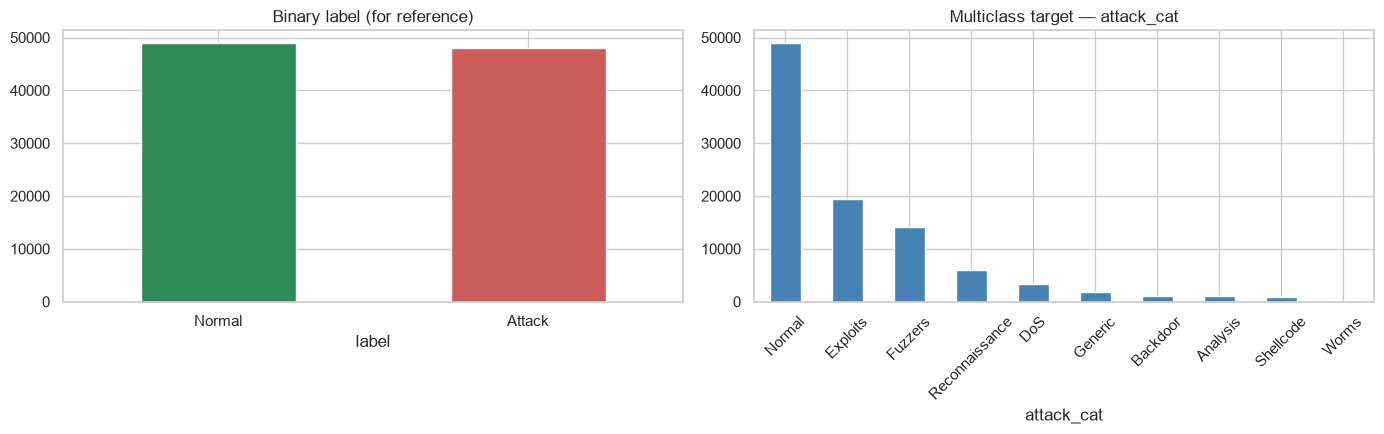

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

train_df[BINARY_COL].map({0: "Normal", 1: "Attack"}).value_counts().plot(
    kind="bar", ax=axes[0], color=["seagreen", "indianred"])
axes[0].set_title("Binary label (for reference)")
axes[0].tick_params(axis="x", rotation=0)

train_df[TARGET_COL].value_counts().plot(kind="bar", ax=axes[1], color="steelblue")
axes[1].set_title("Multiclass target — attack_cat")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 5.2 Attack category distribution

In [18]:
cat_counts = train_df[TARGET_COL].value_counts()
pd.DataFrame({"count": cat_counts, "percent": (cat_counts / cat_counts.sum() * 100).round(2)})

,count,percent
attack_cat,,
Normal,48894,50.50
Exploits,19360,20.00
Fuzzers,14082,14.54
Reconnaissance,6000,6.20
DoS,3369,3.48
Generic,1800,1.86
Backdoor,1121,1.16
Analysis,1119,1.16
Shellcode,954,0.99


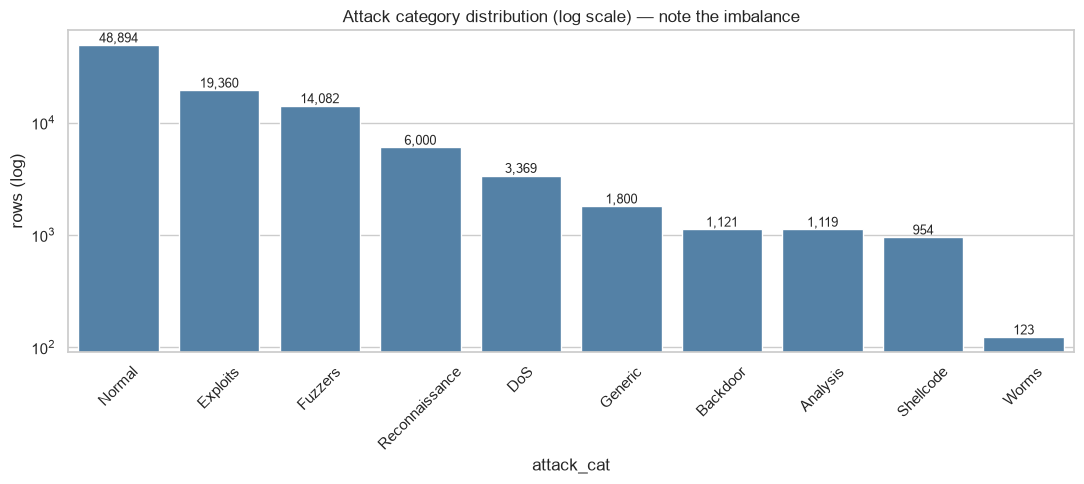

In [19]:
plt.figure(figsize=(11, 5))
ax = sns.barplot(x=cat_counts.index, y=cat_counts.values, color="steelblue")
ax.set_yscale("log")
ax.set_title("Attack category distribution (log scale) — note the imbalance")
ax.set_ylabel("rows (log)")
for i, v in enumerate(cat_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

### 5.3 Categorical distributions

Categorical features: ['proto', 'service', 'state']


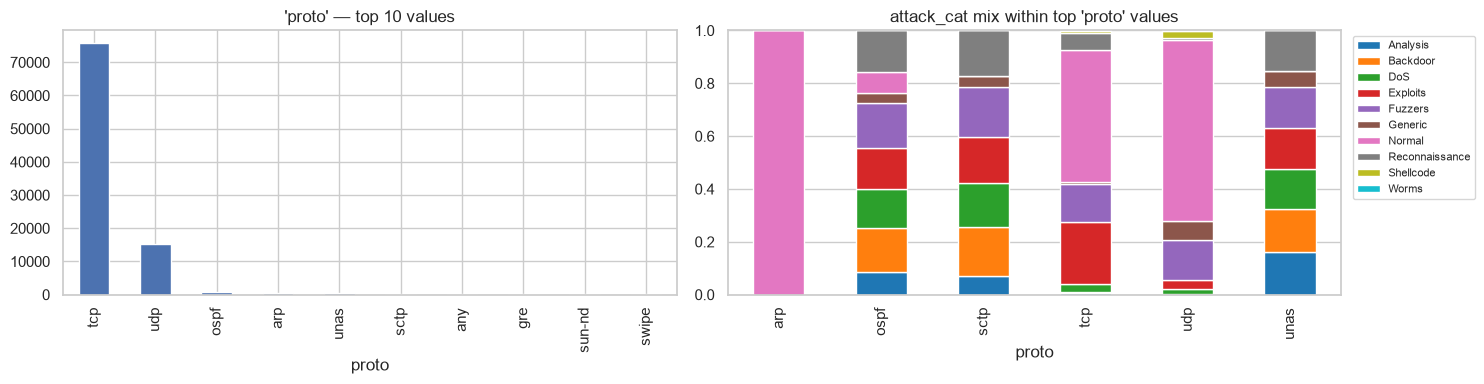

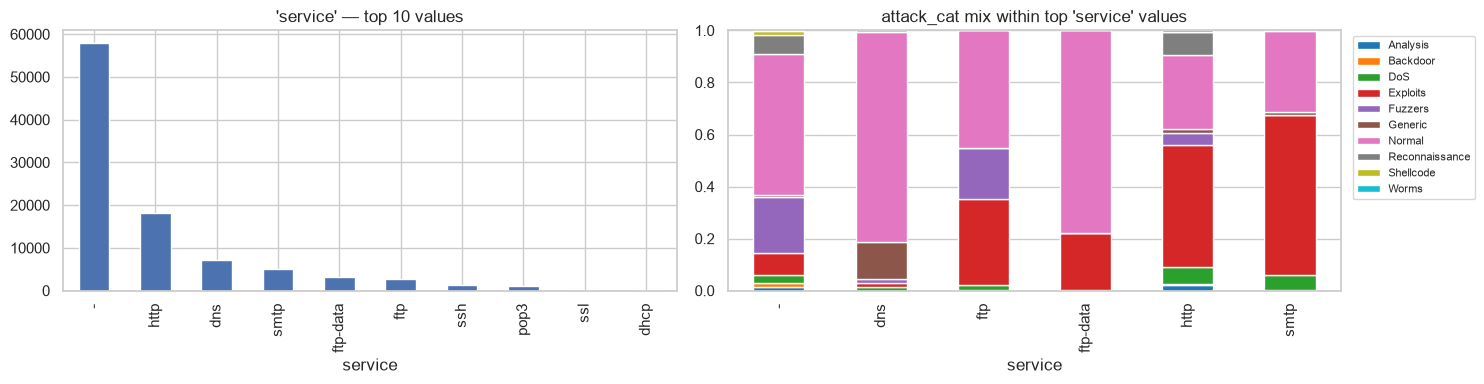

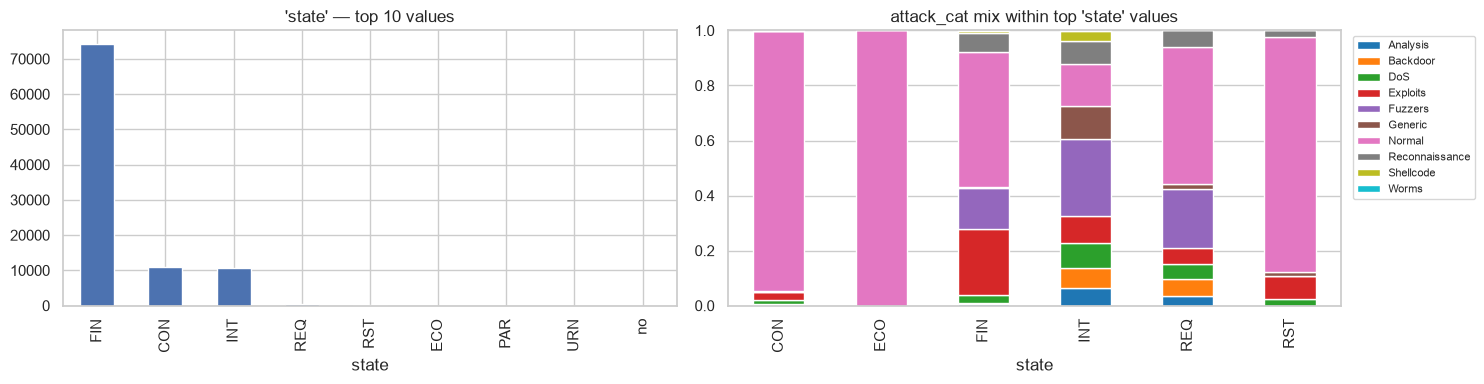

In [20]:
categorical_preview_cols = [c for c in train_df.columns
                            if not pd.api.types.is_numeric_dtype(train_df[c]) and c != TARGET_COL]
print("Categorical features:", categorical_preview_cols)

for col in categorical_preview_cols:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    train_df[col].value_counts().head(10).plot(kind="bar", ax=axes[0], title=f"'{col}' — top 10 values")
    top = train_df[col].value_counts().head(6).index
    (pd.crosstab(train_df.loc[train_df[col].isin(top), col], train_df[TARGET_COL], normalize="index")
       .plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", title=f"attack_cat mix within top '{col}' values"))
    axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

### 5.4 Numerical distributions

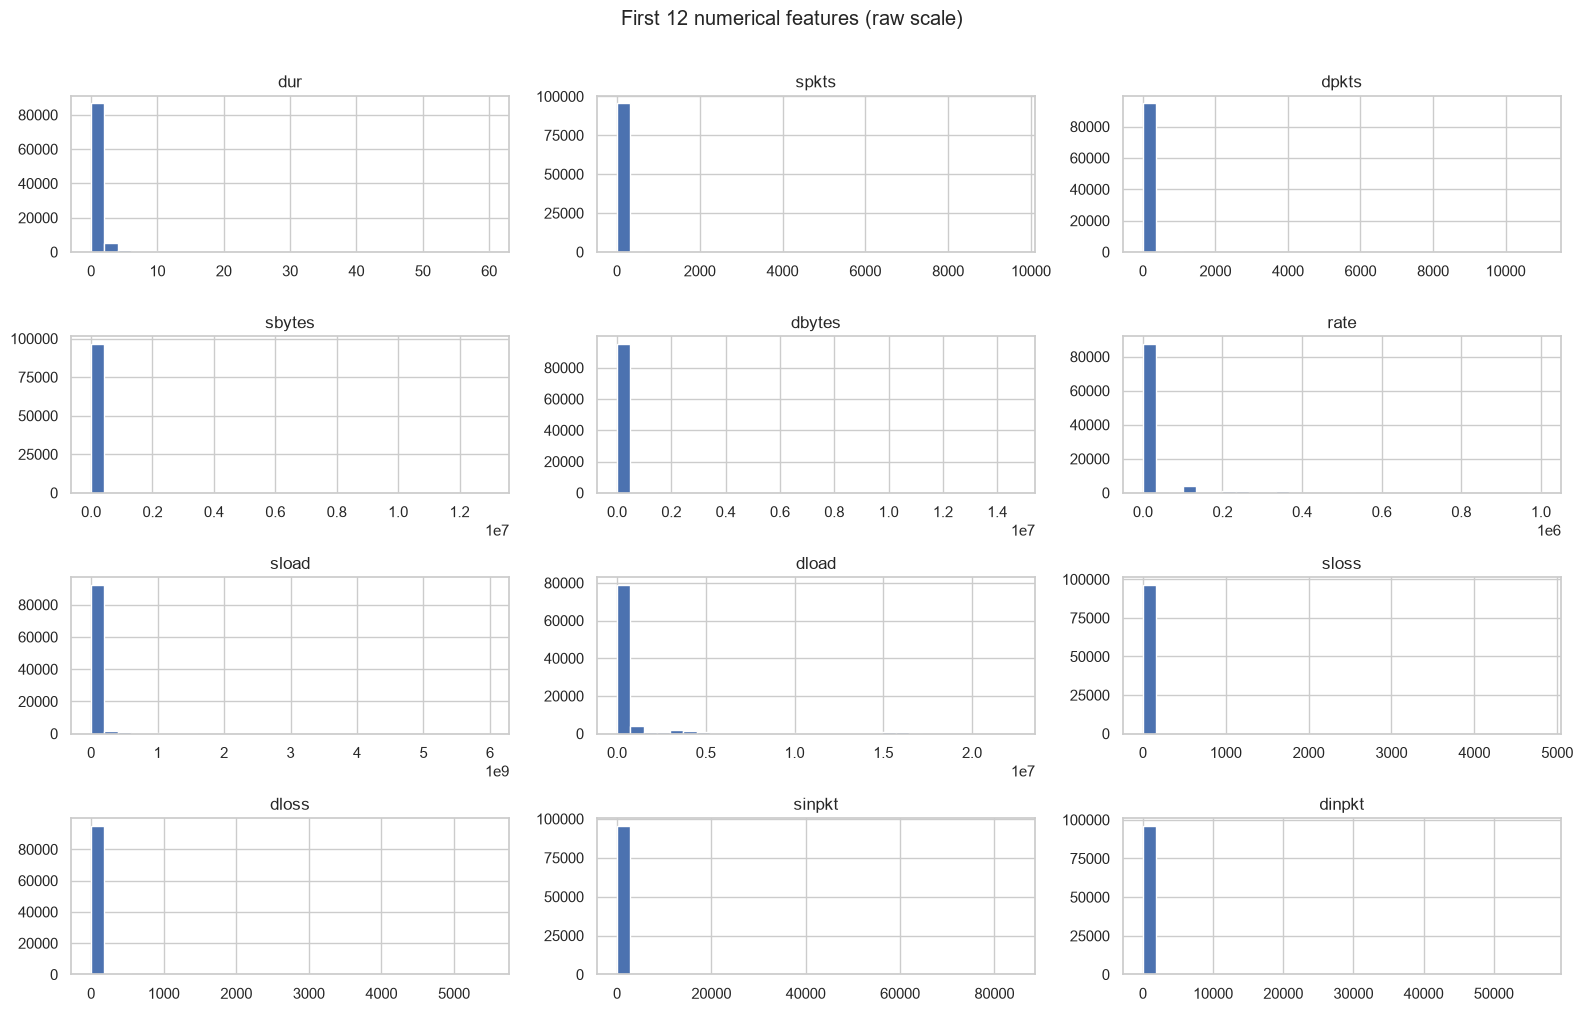

In [21]:
numerical_preview_cols = [c for c in numeric_cols_all if c != ID_COL][:12]
train_df[numerical_preview_cols].hist(figsize=(16, 10), bins=30)
plt.suptitle("First 12 numerical features (raw scale)", y=1.01); plt.tight_layout(); plt.show()

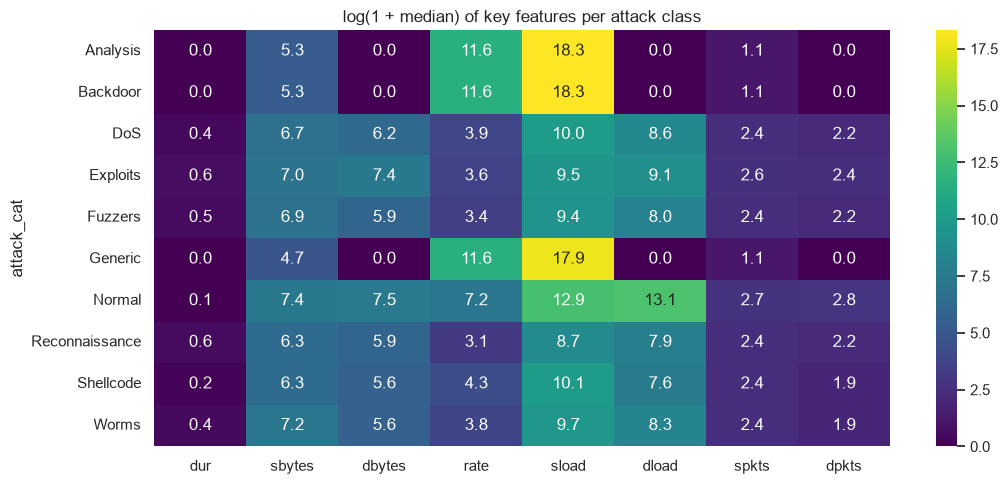

In [22]:
# Heavy right skew is typical for flow features -> compare class medians on a log scale for a few key ones
key_cols = [c for c in ["dur", "sbytes", "dbytes", "rate", "sload", "dload", "spkts", "dpkts"] if c in train_df.columns]
medians = train_df.groupby(TARGET_COL)[key_cols].median()
plt.figure(figsize=(11, 5))
sns.heatmap(np.log1p(medians), annot=True, fmt=".1f", cmap="viridis")
plt.title("log(1 + median) of key features per attack class"); plt.tight_layout(); plt.show()

## Step 6 — Define Target

| Task | Target | Classes |
|---|---|---|
| Binary | `label` | Normal (0) vs Attack (1) |
| **Multiclass (this notebook)** | `attack_cat` | Normal + 9 attack categories |

Both are defined below; every model in this notebook is trained on the multiclass target.

In [23]:
y_binary = train_df[BINARY_COL]        # reference only
y_multi = train_df[TARGET_COL]         # <- modelling target

y_test_binary = test_df[BINARY_COL]
y_test_multi = test_df[TARGET_COL]

print("Multiclass target classes:", sorted(y_multi.unique()))
print("Number of classes:", y_multi.nunique())

Multiclass target classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']
Number of classes: 10


## Step 7 — X / y Separation

In [24]:
drop_cols = [c for c in [ID_COL, TARGET_COL, BINARY_COL] if c in train_df.columns]

X = train_df.drop(columns=drop_cols)
y = y_multi.copy()

X_test_raw = test_df.drop(columns=[c for c in drop_cols if c in test_df.columns])
y_test = y_test_multi.copy()

# Both must have identical feature columns in identical order
X_test_raw = X_test_raw[X.columns]
print("X:", X.shape, "| X_test_raw:", X_test_raw.shape)

X: (96822, 34) | X_test_raw: (82332, 34)


## Step 8 — Identify Data Types

In [25]:
categorical_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]
numerical_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]

print(f"Categorical ({len(categorical_cols)}):", categorical_cols)
print(f"Numerical   ({len(numerical_cols)}):", numerical_cols)
print()
print({c: X[c].nunique() for c in categorical_cols}, "<- unique values per categorical column")

Categorical (3): ['proto', 'service', 'state']
Numerical   (31): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'is_sm_ips_ports']

{'proto': 133, 'service': 13, 'state': 9} <- unique values per categorical column


## Step 9 — Encode Categorical Features

- **Features:** one-hot encoding. The set of dummy columns is defined by the *training* data; the test set is re-indexed to it,
  so categories that never occur in training (e.g. some `state` values that only exist in the test file) become all-zero rows
  instead of creating new columns.
- **Target:** `LabelEncoder` on `attack_cat` → integers `0…9` (alphabetical), required by XGBoost/LightGBM and used for metrics.

In [26]:
X_enc = pd.get_dummies(X, columns=categorical_cols, dtype=float)
ohe_columns = X_enc.columns.tolist()

X_test_enc = pd.get_dummies(X_test_raw, columns=categorical_cols, dtype=float).reindex(columns=ohe_columns, fill_value=0.0)

unseen = {c: sorted(set(X_test_raw[c]) - set(X[c])) for c in categorical_cols}
print("Categories present in test but never seen in train:", {k: v for k, v in unseen.items() if v} or "None")
print("Encoded shape — train:", X_enc.shape, "| test:", X_test_enc.shape)

Categories present in test but never seen in train: {'state': ['ACC', 'CLO']}
Encoded shape — train: (96822, 186) | test: (82332, 186)


In [27]:
target_encoder = LabelEncoder()
y_enc = pd.Series(target_encoder.fit_transform(y), index=y.index, name="attack_cat_encoded")
y_test_enc = pd.Series(target_encoder.transform(y_test), index=y_test.index, name="attack_cat_encoded")

class_names = list(target_encoder.classes_)
n_classes = len(class_names)
normal_id = class_names.index("Normal")
attack_ids = [i for i in range(n_classes) if i != normal_id]

print(dict(zip(class_names, range(n_classes))))

{'Analysis': 0, 'Backdoor': 1, 'DoS': 2, 'Exploits': 3, 'Fuzzers': 4, 'Generic': 5, 'Normal': 6, 'Reconnaissance': 7, 'Shellcode': 8, 'Worms': 9}


## Step 10 — Train / Validation Split

Stratified 80/20 so every class — including `Worms` — appears in both parts in the same proportion.

In [28]:
X_train, X_val, y_train, y_val = train_test_split(
    X_enc, y_enc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_enc
)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test_enc.shape)

pd.DataFrame({
    "train": pd.Series(y_train).map(dict(enumerate(class_names))).value_counts(),
    "validation": pd.Series(y_val).map(dict(enumerate(class_names))).value_counts(),
    "test": pd.Series(y_test_enc).map(dict(enumerate(class_names))).value_counts(),
})

Train: (77457, 186) | Validation: (19365, 186) | Test: (82332, 186)


,train,validation,test
attack_cat_encoded,,,
Analysis,895,224,677
Backdoor,897,224,583
DoS,2695,674,4089
Exploits,15488,3872,11132
Fuzzers,11266,2816,6062
Generic,1440,360,18871
Normal,39115,9779,37000
Reconnaissance,4800,1200,3496
Shellcode,763,191,378


## Step 11 — Feature Scaling

The scaler is fitted on the training split only, then applied to validation and test.

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test_enc)

feature_columns = X_train.columns.tolist()
y_train_arr, y_val_arr, y_test_arr = y_train.to_numpy(), y_val.to_numpy(), y_test_enc.to_numpy()
print("Scaled shapes:", X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

Scaled shapes: (77457, 186) (19365, 186) (82332, 186)


## Step 12 — Handle Class Imbalance

Three options are compared with the *same* Logistic Regression so the only thing that changes is the imbalance handling:

1. **Nothing** — baseline.
2. **Class weights** — no new rows; errors on rare classes are penalised more.
3. **SMOTE** — synthesises minority-class rows. Oversampling every class up to the size of `Normal` would create hundreds of thousands of
   synthetic rows (and ~50× synthetic copies of `Worms`), so classes are lifted to at most `SMOTE_TARGET` rows; larger classes are untouched.

SMOTE is used for the models from Step 14 onward. Only the training split is resampled — validation and test stay untouched.

In [30]:
class_weights_array = compute_class_weight(class_weight="balanced", classes=np.arange(n_classes), y=y_train_arr)
class_weight_dict = dict(zip(range(n_classes), class_weights_array))
print(pd.Series({class_names[k]: round(v, 2) for k, v in class_weight_dict.items()}, name="balanced class weight"))

Analysis           8.65
Backdoor           8.64
DoS                2.87
Exploits           0.50
Fuzzers            0.69
Generic            5.38
Normal             0.20
Reconnaissance     1.61
Shellcode         10.15
Worms             79.04
Name: balanced class weight, dtype: float64


In [31]:
SMOTE_TARGET = 5000   # minimum rows per class after SMOTE (classes already larger are left as they are)

def smote_strategy(y, target=SMOTE_TARGET):
    counts = Counter(y)
    return {cls: target for cls, n in counts.items() if n < target}

min_count = pd.Series(y_train_arr).value_counts().min()
smote = SMOTE(sampling_strategy=smote_strategy, k_neighbors=max(1, min(5, min_count - 1)), random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train_arr)

before_after = pd.DataFrame({
    "before SMOTE": pd.Series(y_train_arr).value_counts().sort_index(),
    "after SMOTE": pd.Series(y_train_res).value_counts().sort_index(),
})
before_after.index = class_names
print("Rows: ", len(y_train_arr), "->", len(y_train_res))
before_after

Rows:  77457 -> 100869


,before SMOTE,after SMOTE
Analysis,895,5000
Backdoor,897,5000
DoS,2695,5000
Exploits,15488,15488
Fuzzers,11266,11266
Generic,1440,5000
Normal,39115,39115
Reconnaissance,4800,5000
Shellcode,763,5000
Worms,98,5000


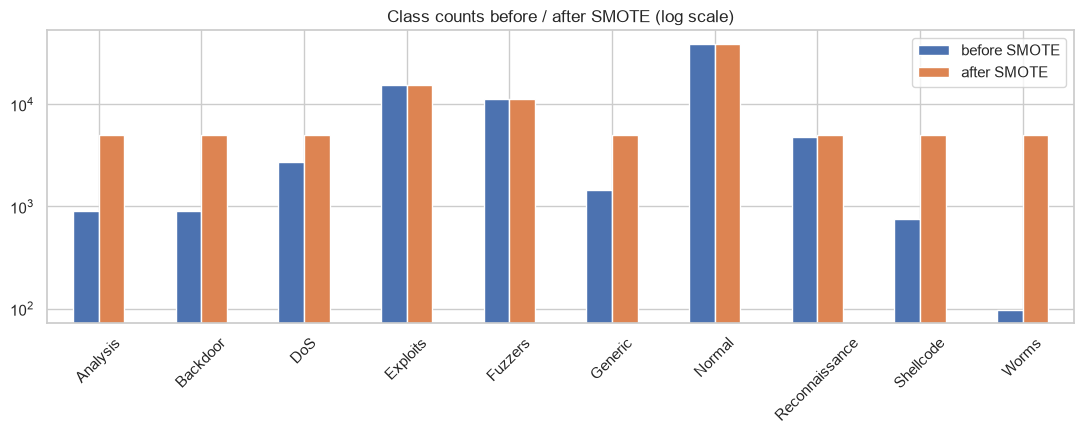

In [32]:
ax = before_after.plot(kind="bar", figsize=(11, 4.5), logy=True, title="Class counts before / after SMOTE (log scale)")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

In [33]:
# Compare before / after on the SAME model (Logistic Regression) — validation split
def lr_report(name, **fit):
    lr = LogisticRegression(max_iter=500, random_state=RANDOM_STATE, **fit["params"])
    lr.fit(*fit["data"])
    pred = lr.predict(X_val_scaled)
    per_class = f1_score(y_val_arr, pred, average=None, labels=range(n_classes), zero_division=0)
    return {"strategy": name,
            "accuracy": accuracy_score(y_val_arr, pred),
            "f1_macro": f1_score(y_val_arr, pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_val_arr, pred, average="macro", zero_division=0),
            **{f"F1 {c}": v for c, v in zip(class_names, per_class)}}

imbalance_cmp = pd.DataFrame([
    lr_report("No handling", params={}, data=(X_train_scaled, y_train_arr)),
    lr_report("Class weights", params={"class_weight": class_weight_dict}, data=(X_train_scaled, y_train_arr)),
    lr_report("SMOTE", params={}, data=(X_train_res, y_train_res)),
]).set_index("strategy")
imbalance_cmp.round(3).T

strategy,No handling,Class weights,SMOTE
accuracy,0.711,0.636,0.693
f1_macro,0.379,0.394,0.412
recall_macro,0.373,0.544,0.495
F1 Analysis,0.080,0.157,0.176
F1 Backdoor,0.067,0.200,0.179
F1 DoS,0.042,0.080,0.053
F1 Exploits,0.705,0.559,0.669
F1 Fuzzers,0.560,0.588,0.561
F1 Generic,0.684,0.651,0.666
F1 Normal,0.857,0.845,0.860


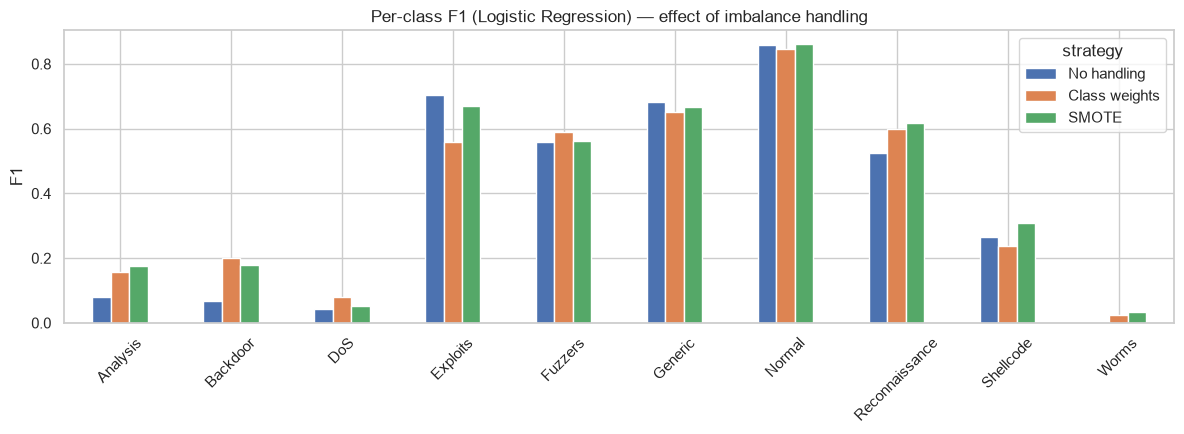

In [34]:
imbalance_cmp[[f"F1 {c}" for c in class_names]].T.rename(index=lambda s: s.replace("F1 ", "")).plot(
    kind="bar", figsize=(12, 4.5), title="Per-class F1 (Logistic Regression) — effect of imbalance handling")
plt.ylabel("F1"); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## Step 13 — Feature Selection

1. **Correlation analysis** on the encoded training features (correlation is unaffected by standardisation).
2. **Importance** from a quick class-balanced Random Forest.
3. **Remove unnecessary features** — constant columns (e.g. one-hot columns that never occur in training) and, for every pair correlated above 0.95,
   the member with lower importance.

The resulting column indices are applied to the scaled and the SMOTE-resampled arrays.

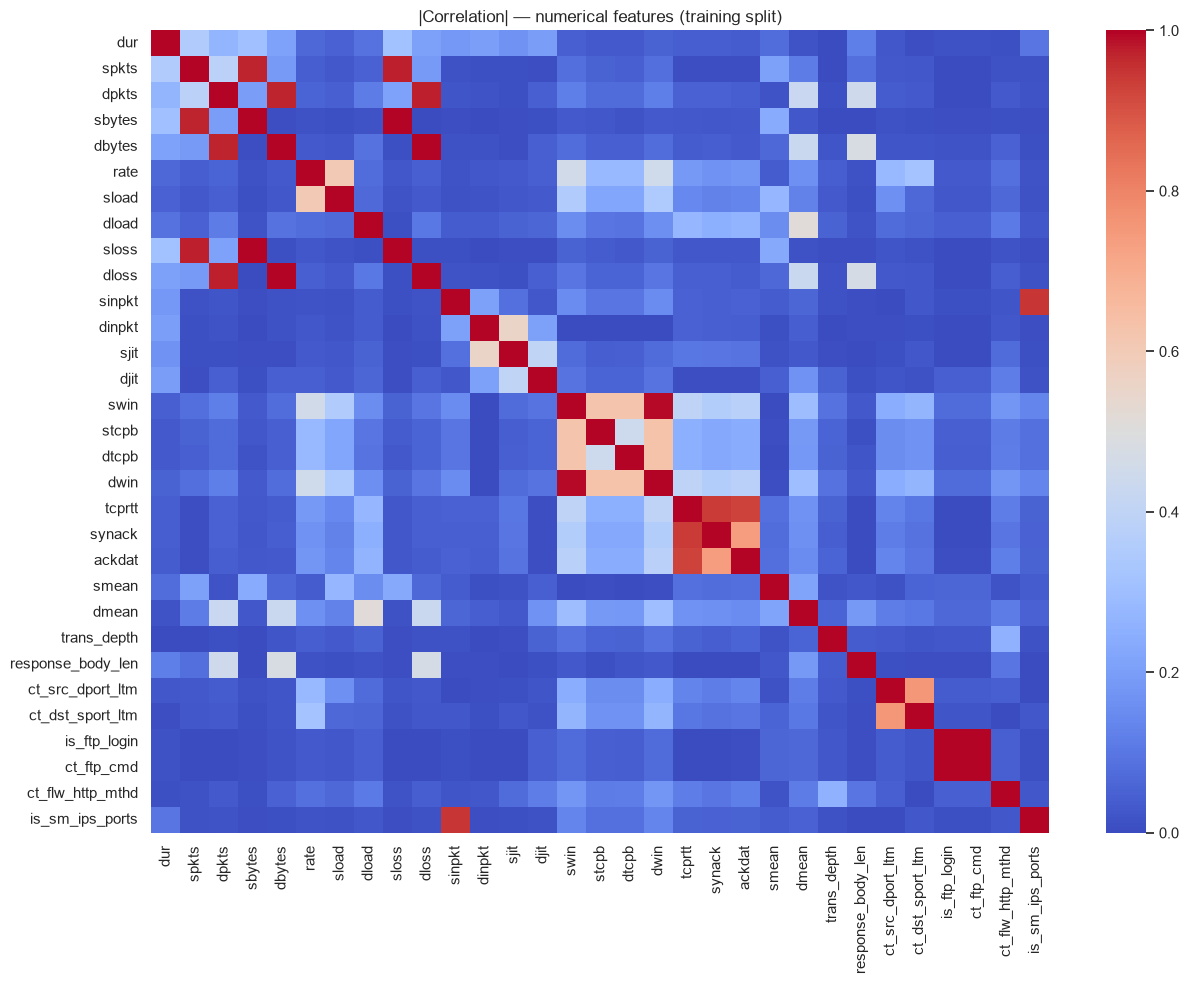

In [35]:
numeric_corr = X_train[numerical_cols].corr().abs()
plt.figure(figsize=(13, 10))
sns.heatmap(numeric_corr, cmap="coolwarm", vmin=0, vmax=1)
plt.title("|Correlation| — numerical features (training split)"); plt.tight_layout(); plt.show()

In [36]:
non_constant = X_train.columns[X_train.std() > 0]
constant_cols = sorted(set(X_train.columns) - set(non_constant))
print(f"{len(constant_cols)} constant (zero-variance) columns in training data")

corr_matrix = X_train[non_constant].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pairs = (upper.stack().rename("corr").reset_index()
         .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
         .query("corr > 0.95").sort_values("corr", ascending=False))
print(f"{len(pairs)} feature pairs with |corr| > 0.95")
pairs.head(20)

2 constant (zero-variance) columns in training data
13 feature pairs with |corr| > 0.95


,feature_a,feature_b,corr
4996,is_ftp_login,ct_ftp_cmd,1.000000
2719,swin,proto_tcp,0.999901
560,sbytes,sloss,0.997257
745,dbytes,dloss,0.996651
3271,dwin,proto_tcp,0.993052
2593,swin,dwin,0.993004
377,dpkts,dloss,0.976233
192,spkts,sloss,0.976022
372,dpkts,dbytes,0.970400
187,spkts,sbytes,0.969721


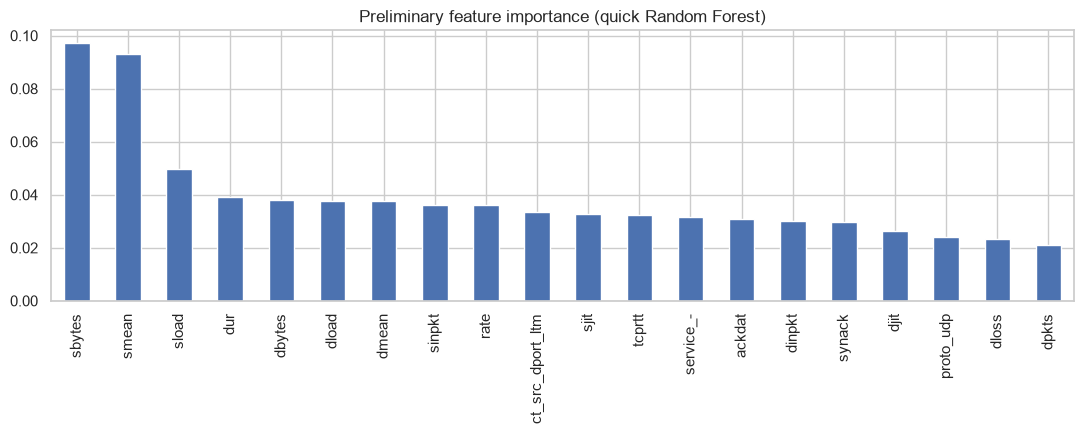

In [37]:
quick_rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
quick_rf.fit(X_train_scaled, y_train_arr)
quick_importance = pd.Series(quick_rf.feature_importances_, index=feature_columns)

quick_importance.sort_values(ascending=False).head(20).plot(
    kind="bar", figsize=(11, 4.5), title="Preliminary feature importance (quick Random Forest)")
plt.tight_layout(); plt.show()

In [38]:
to_drop = set(constant_cols)
for a, b in zip(pairs["feature_a"], pairs["feature_b"]):
    if a in to_drop or b in to_drop:
        continue                                   # pair already resolved
    to_drop.add(a if quick_importance[a] < quick_importance[b] else b)

keep_idx = [i for i, c in enumerate(feature_columns) if c not in to_drop]
feature_columns_selected = [feature_columns[i] for i in keep_idx]

print(f"Dropping {len(to_drop)} features ({len(constant_cols)} constant + {len(to_drop) - len(constant_cols)} redundant)")
print("Redundant features dropped:", sorted(to_drop - set(constant_cols)))
print("Feature count before:", len(feature_columns), "| after:", len(feature_columns_selected))

X_train_sel = X_train_scaled[:, keep_idx]        # un-resampled (used for tuning with in-fold SMOTE)
X_train_res_sel = X_train_res[:, keep_idx]       # SMOTE-resampled (used to fit the models)
X_val_sel = X_val_scaled[:, keep_idx]
X_test_sel = X_test_scaled[:, keep_idx]

Dropping 10 features (2 constant + 8 redundant)
Redundant features dropped: ['ct_ftp_cmd', 'dloss', 'dpkts', 'dwin', 'proto_tcp', 'sloss', 'spkts', 'swin']
Feature count before: 186 | after: 176


### Evaluation helper (used from here on)

One function computes every metric so models are always compared the same way.

| Metric | Meaning in the multiclass setting |
|---|---|
| `f1_macro`, `recall_macro`, `precision_macro` | unweighted mean over the 10 classes — rare classes count as much as `Normal` |
| `roc_auc_ovr`, `pr_auc_macro` | one-vs-rest ROC-AUC / average precision, macro-averaged |
| `minority_f1` | mean F1 over the *minority classes* (< 5 % of the training data) |
| `macro_fpr` | per-class false-positive rate, averaged over classes |
| `normal_false_alarm_rate` | share of `Normal` traffic flagged as any attack (analyst workload) |
| `attack_miss_rate` | share of attack traffic classified as `Normal` (missed intrusions) |

In [39]:
train_share = pd.Series(y_train_arr).value_counts(normalize=True)
minority_ids = sorted(train_share[train_share < 0.05].index.tolist())
print("Minority classes (< 5 % of training data):", [class_names[i] for i in minority_ids])

def evaluate_model(model, X, y_true):
    y_pred = model.predict(X)
    proba = model.predict_proba(X)
    labels = np.arange(n_classes)
    y_bin = label_binarize(y_true, classes=labels)

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp = np.diag(cm); fp = cm.sum(axis=0) - tp; fn = cm.sum(axis=1) - tp; tn = cm.sum() - tp - fp - fn
    fpr_per_class = fp / np.maximum(fp + tn, 1)

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc_ovr": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=labels),
        "pr_auc_macro": np.mean([average_precision_score(y_bin[:, k], proba[:, k]) for k in labels]),
        "minority_f1": f1_score(y_true, y_pred, labels=minority_ids, average="macro", zero_division=0),
        "macro_fpr": fpr_per_class.mean(),
        "normal_false_alarm_rate": 1 - cm[normal_id, normal_id] / max(cm[normal_id].sum(), 1),
        "attack_miss_rate": cm[attack_ids, normal_id].sum() / max(cm[attack_ids].sum(), 1),
    }

fitted_models, val_results = {}, {}

def fit_and_record(name, model, show_report=True):
    model.fit(X_train_res_sel, y_train_res)
    fitted_models[name] = model
    val_results[name] = evaluate_model(model, X_val_sel, y_val_arr)
    r = val_results[name]
    print(f"=== {name} — validation: accuracy {r['accuracy']:.4f} | macro-F1 {r['f1_macro']:.4f} | macro-recall {r['recall_macro']:.4f} ===")
    if show_report:
        print(classification_report(y_val_arr, model.predict(X_val_sel), target_names=class_names, zero_division=0, digits=3))

Minority classes (< 5 % of training data): ['Analysis', 'Backdoor', 'DoS', 'Generic', 'Shellcode', 'Worms']


## Step 14 — Baseline Models

In [40]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}
for name, clf in baseline_models.items():
    fit_and_record(name, clf)

=== Logistic Regression — validation: accuracy 0.6754 | macro-F1 0.3998 | macro-recall 0.4710 ===
                precision    recall  f1-score   support

      Analysis      0.115     0.344     0.172       224
      Backdoor      0.133     0.304     0.185       224
           DoS      0.185     0.015     0.027       674
      Exploits      0.752     0.547     0.633      3872
       Fuzzers      0.510     0.575     0.540      2816
       Generic      0.837     0.556     0.668       360
        Normal      0.856     0.831     0.843      9779
Reconnaissance      0.573     0.618     0.595      1200
     Shellcode      0.205     0.602     0.306       191
         Worms      0.014     0.320     0.028        25

      accuracy                          0.675     19365
     macro avg      0.418     0.471     0.400     19365
  weighted avg      0.719     0.675     0.688     19365

=== Decision Tree — validation: accuracy 0.7654 | macro-F1 0.4805 | macro-recall 0.5031 ===
                precisi

## Step 15 — Advanced Models (XGBoost, LightGBM)

In [41]:
advanced_models = {
    "XGBoost": XGBClassifier(
        objective="multi:softprob", n_estimators=200, max_depth=6, learning_rate=0.1,
        tree_method="hist", eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1),
    "LightGBM": LGBMClassifier(
        objective="multiclass", n_estimators=200, learning_rate=0.1,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1),
}
for name, clf in advanced_models.items():
    fit_and_record(name, clf)

=== XGBoost — validation: accuracy 0.8086 | macro-F1 0.5514 | macro-recall 0.6145 ===
                precision    recall  f1-score   support

      Analysis      0.150     0.424     0.222       224
      Backdoor      0.183     0.487     0.266       224
           DoS      0.574     0.174     0.267       674
      Exploits      0.833     0.825     0.829      3872
       Fuzzers      0.711     0.701     0.706      2816
       Generic      0.823     0.669     0.738       360
        Normal      0.931     0.909     0.920      9779
Reconnaissance      0.864     0.738     0.796      1200
     Shellcode      0.358     0.738     0.482       191
         Worms      0.207     0.480     0.289        25

      accuracy                          0.809     19365
     macro avg      0.563     0.614     0.551     19365
  weighted avg      0.836     0.809     0.816     19365

=== LightGBM — validation: accuracy 0.8061 | macro-F1 0.5354 | macro-recall 0.5573 ===
                precision    recall  f1-

## Step 16 — Hyperparameter Tuning

`RandomizedSearchCV` for Random Forest (broad, cheap) and `GridSearchCV` for XGBoost (small, focused grid), both scored with **`f1_macro`**.

Two design choices keep the search honest and fast:
- The search runs on a stratified **subsample** of the *un-resampled* training data, with **SMOTE inside the CV pipeline**. Tuning on data that was already
  oversampled would let synthetic neighbours of a training row leak into its own validation fold and inflate the scores.
- The winning parameters are then **re-fitted on the full SMOTE-resampled training set**, the same data the other models use.

In [42]:
TUNE_N = 40000            # rows used for the search (all rows if the training set is smaller)
TUNE_SMOTE_TARGET = 2000  # smaller SMOTE cap inside the CV folds, matched to the subsample size

if len(y_train_arr) > TUNE_N:
    X_tune, _, y_tune, _ = train_test_split(X_train_sel, y_train_arr, train_size=TUNE_N,
                                            stratify=y_train_arr, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train_sel, y_train_arr

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def tuning_pipeline(clf):
    return ImbPipeline([
        ("smote", SMOTE(sampling_strategy=partial(smote_strategy, target=TUNE_SMOTE_TARGET),
                        k_neighbors=3, random_state=RANDOM_STATE)),
        ("clf", clf),
    ])

strip = lambda params: {k.replace("clf__", ""): v for k, v in params.items()}
print("Tuning subsample:", X_tune.shape)

Tuning subsample: (40000, 176)


In [43]:
rf_param_dist = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [None, 15, 25],
    "clf__min_samples_split": [2, 5, 10],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2"],
}
rf_search = RandomizedSearchCV(
    tuning_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)),
    param_distributions=rf_param_dist, n_iter=10, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
rf_search.fit(X_tune, y_tune)

print("Best RF params (RandomizedSearchCV):", strip(rf_search.best_params_))
print(f"Best RF CV macro-F1: {rf_search.best_score_:.4f}")

fit_and_record("Random Forest (tuned)",
               RandomForestClassifier(**strip(rf_search.best_params_), random_state=RANDOM_STATE, n_jobs=-1),
               show_report=False)
best_rf = fitted_models["Random Forest (tuned)"]

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best RF params (RandomizedSearchCV): {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 25}
Best RF CV macro-F1: 0.5329
=== Random Forest (tuned) — validation: accuracy 0.7971 | macro-F1 0.5140 | macro-recall 0.5593 ===


In [44]:
xgb_param_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [4, 6, 8],
    "clf__learning_rate": [0.05, 0.1],
}
xgb_search = GridSearchCV(
    tuning_pipeline(XGBClassifier(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                                  random_state=RANDOM_STATE, n_jobs=1)),
    param_grid=xgb_param_grid, scoring="f1_macro", cv=cv, n_jobs=-1, verbose=1,
)
xgb_search.fit(X_tune, y_tune)

print("Best XGBoost params (GridSearchCV):", strip(xgb_search.best_params_))
print(f"Best XGBoost CV macro-F1: {xgb_search.best_score_:.4f}")

fit_and_record("XGBoost (tuned)",
               XGBClassifier(objective="multi:softprob", tree_method="hist", eval_metric="mlogloss",
                             **strip(xgb_search.best_params_), random_state=RANDOM_STATE, n_jobs=-1),
               show_report=False)
best_xgb = fitted_models["XGBoost (tuned)"]

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best XGBoost params (GridSearchCV): {'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 200}
Best XGBoost CV macro-F1: 0.5575
=== XGBoost (tuned) — validation: accuracy 0.8087 | macro-F1 0.5554 | macro-recall 0.6156 ===


## Step 17 — Feature Importance (Random Forest, XGBoost, LightGBM)

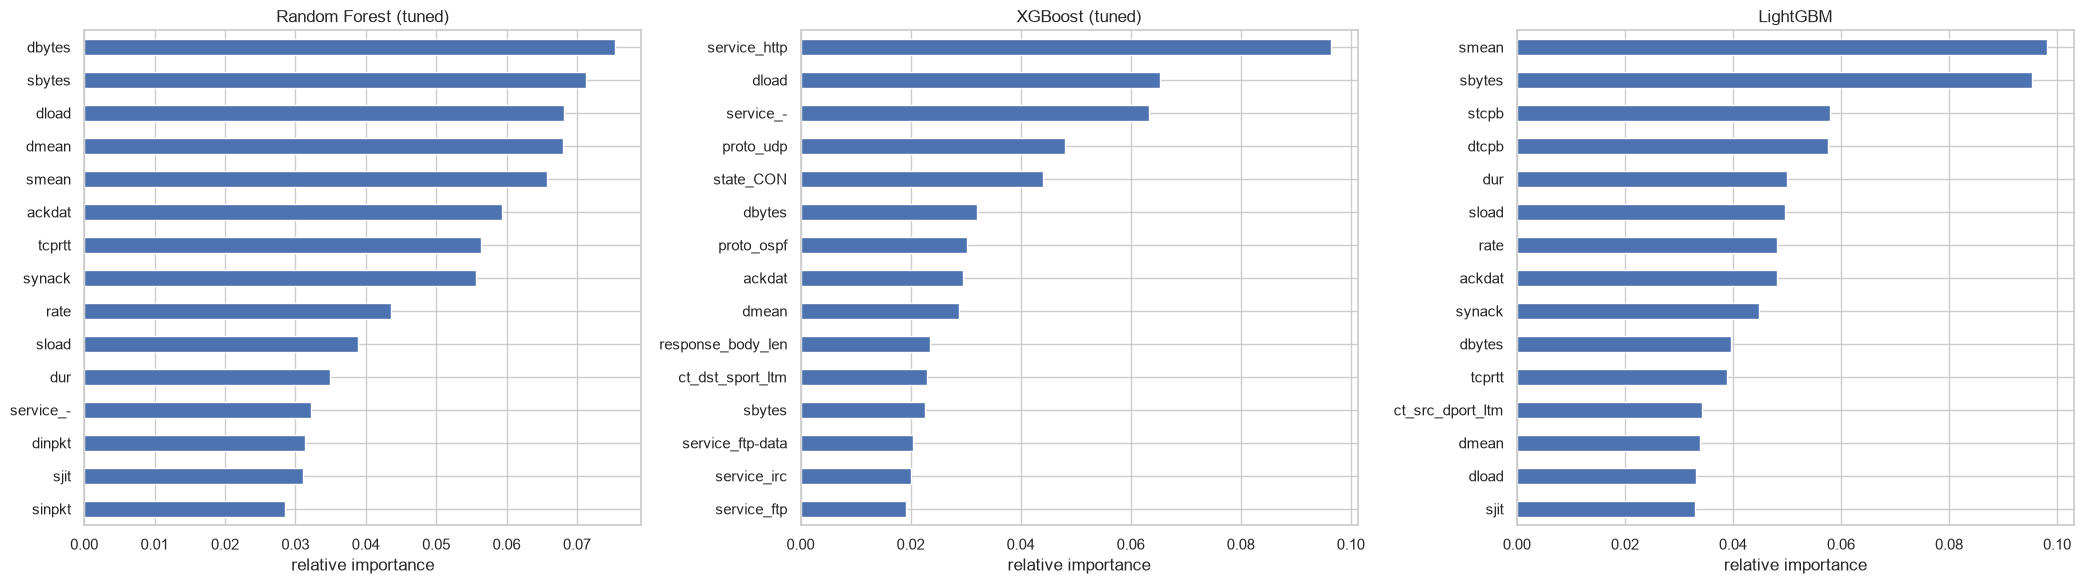

In [45]:
importances = {
    "Random Forest (tuned)": pd.Series(best_rf.feature_importances_, index=feature_columns_selected),
    "XGBoost (tuned)": pd.Series(best_xgb.feature_importances_, index=feature_columns_selected),
    "LightGBM": pd.Series(fitted_models["LightGBM"].feature_importances_, index=feature_columns_selected),
}
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, (name, imp) in zip(axes, importances.items()):
    (imp / imp.sum()).sort_values(ascending=True).tail(15).plot(kind="barh", ax=ax, title=name)
    ax.set_xlabel("relative importance")
plt.tight_layout(); plt.show()

In [46]:
# Features that all three models rank in their top 15
top15 = [set(((imp / imp.sum()).sort_values(ascending=False)).head(15).index) for imp in importances.values()]
print("Top-15 in all three models:", sorted(set.intersection(*top15)))

Top-15 in all three models: ['ackdat', 'dbytes', 'dload', 'dmean', 'sbytes']


## Step 18 — SHAP Explainability

`TreeExplainer` on the tuned Random Forest. For a multiclass model SHAP produces **one set of values per class** (array shape `samples × features × classes`),
so the outputs below are:

1. **Global** — mean |SHAP| per feature, stacked by class, and a per-class beeswarm.
2. **Individual** — waterfall plot explaining one prediction for the class the model actually predicted.

In [47]:
SHAP_SAMPLE = 300
shap_sample = pd.DataFrame(X_val_sel, columns=feature_columns_selected).sample(
    n=min(SHAP_SAMPLE, len(X_val_sel)), random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(best_rf)
sv = explainer.shap_values(shap_sample, check_additivity=False)

# Normalise across SHAP versions -> (samples, features, classes)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
print("SHAP values shape (samples, features, classes):", sv.shape)

SHAP values shape (samples, features, classes): (300, 176, 10)


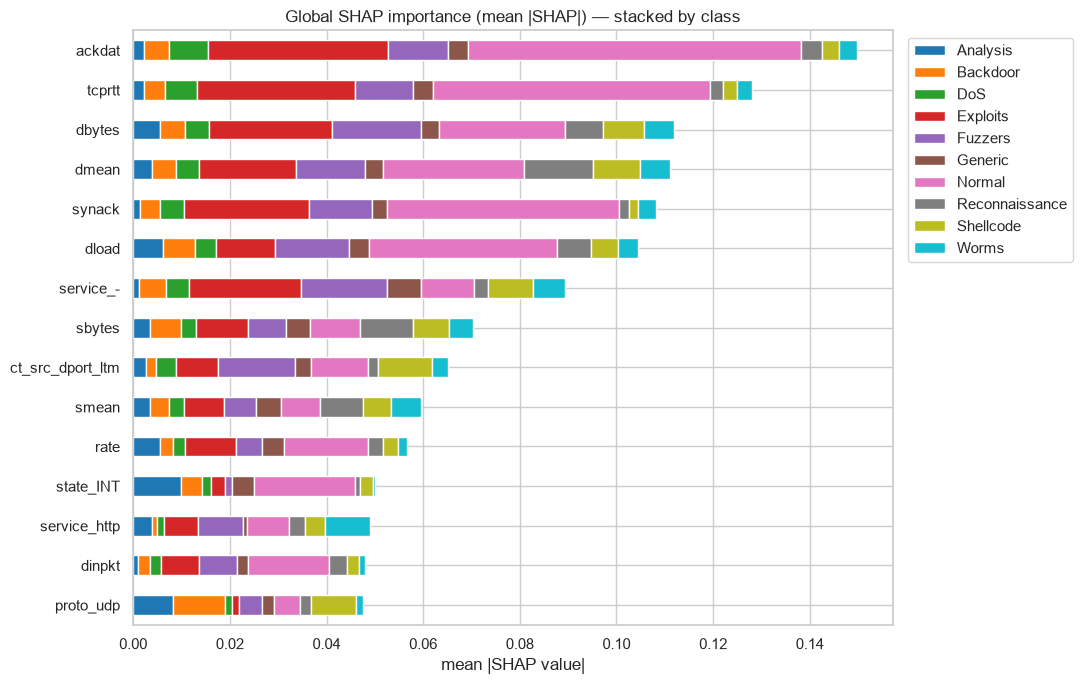

In [48]:
# Global importance: mean |SHAP| per feature, stacked by class
mean_abs = pd.DataFrame(np.abs(sv).mean(axis=0), index=feature_columns_selected, columns=class_names)
top_features = mean_abs.sum(axis=1).sort_values(ascending=False).head(15).index

mean_abs.loc[top_features].iloc[::-1].plot(kind="barh", stacked=True, figsize=(11, 7), colormap="tab10")
plt.title("Global SHAP importance (mean |SHAP|) — stacked by class")
plt.xlabel("mean |SHAP value|"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

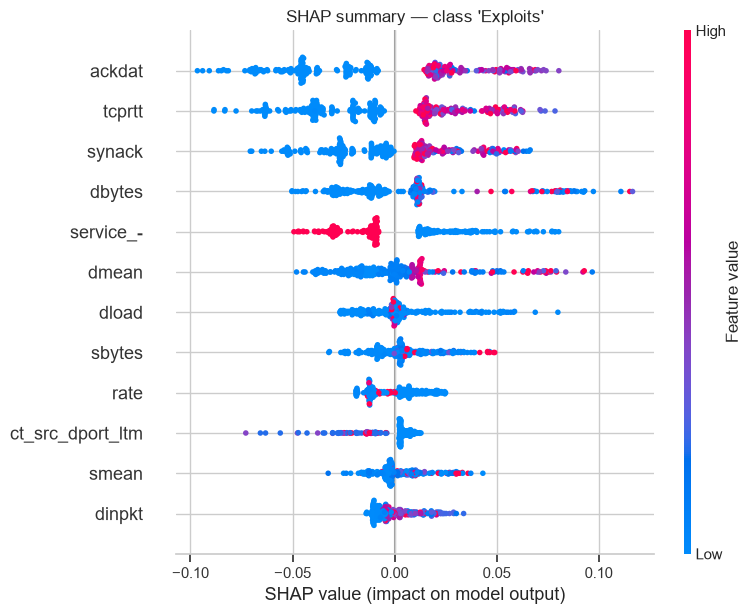

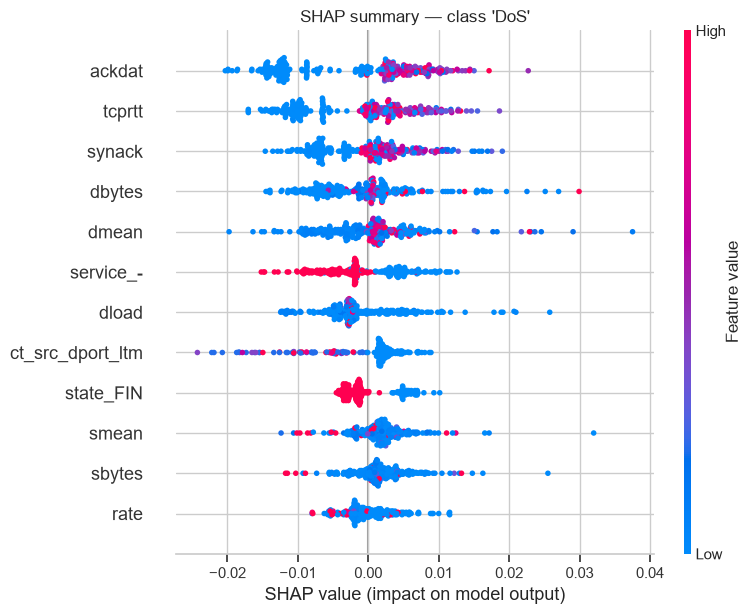

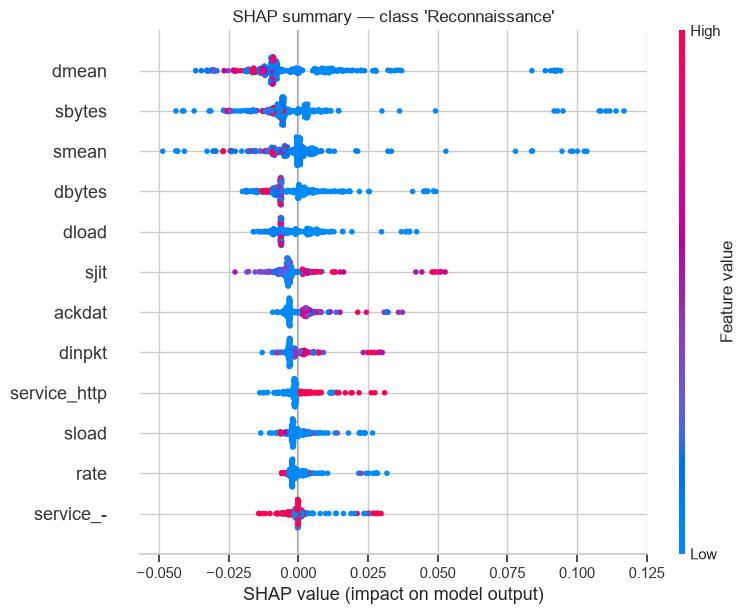

In [49]:
# Per-class beeswarm (which feature values push a flow TOWARD this class?)
for cls in [c for c in ["Exploits", "DoS", "Reconnaissance"] if c in class_names]:
    k = class_names.index(cls)
    plt.figure()
    shap.summary_plot(sv[:, :, k], shap_sample, max_display=12, show=False)
    plt.title(f"SHAP summary — class '{cls}'")
    plt.tight_layout(); plt.show()

Predicted class: Fuzzers (p = 0.70)


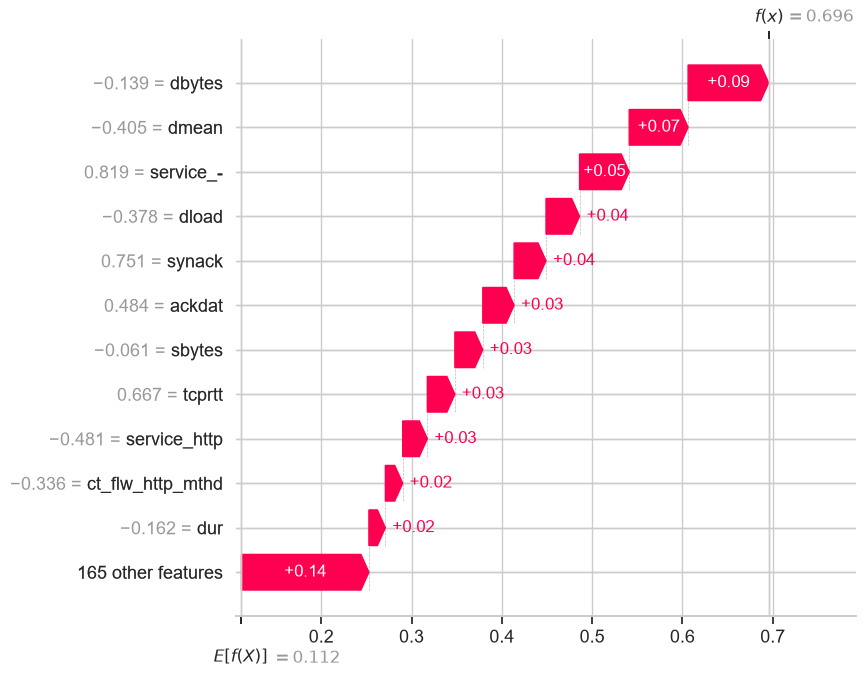

In [50]:
# Individual prediction: explain the class the model actually predicted for one validation flow
instance_idx = 0
proba_inst = best_rf.predict_proba(shap_sample.iloc[[instance_idx]].to_numpy())[0]
pred_k = int(np.argmax(proba_inst))
base_values = np.atleast_1d(explainer.expected_value)

print(f"Predicted class: {class_names[pred_k]} (p = {proba_inst[pred_k]:.2f})")
explanation = shap.Explanation(
    values=sv[instance_idx, :, pred_k],
    base_values=base_values[pred_k],
    data=shap_sample.iloc[instance_idx].to_numpy(),
    feature_names=feature_columns_selected,
)
shap.plots.waterfall(explanation, max_display=12, show=True)

## Step 19 — Model Evaluation (Validation Split)

Every model is scored with the full metric set. Diagnostics (classification report, confusion matrices, per-class ROC and precision-recall curves)
are then shown for the current leader by macro-F1.

In [51]:
val_df = pd.DataFrame(val_results).T
val_df.sort_values("f1_macro", ascending=False).round(4)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,pr_auc_macro,minority_f1,macro_fpr,normal_false_alarm_rate,attack_miss_rate
XGBoost (tuned),0.8087,0.5644,0.6156,0.5554,0.8168,0.9708,0.5940,0.3831,0.0242,0.0933,0.0672
XGBoost,0.8086,0.5632,0.6145,0.5514,0.8160,0.9683,0.5859,0.3772,0.0243,0.0910,0.0690
LightGBM,0.8061,0.5385,0.5573,0.5354,0.8122,0.9679,0.5833,0.3551,0.0249,0.0860,0.0746
Random Forest (tuned),0.7971,0.5565,0.5593,0.5140,0.8044,0.9654,0.5493,0.3230,0.0252,0.1038,0.0578
Random Forest,0.7944,0.5158,0.5302,0.5137,0.7963,0.9391,0.5300,0.3345,0.0265,0.0984,0.0747
Decision Tree,0.7654,0.4764,0.5031,0.4805,0.7783,0.7351,0.3515,0.2883,0.0301,0.0995,0.0936
Logistic Regression,0.6754,0.4180,0.4710,0.3998,0.6884,0.9075,0.3934,0.2310,0.0422,0.1692,0.1428


In [52]:
leader_name = val_df["f1_macro"].idxmax()
leader = fitted_models[leader_name]
y_val_pred = leader.predict(X_val_sel)
y_val_proba = leader.predict_proba(X_val_sel)

print(f"Leader on validation macro-F1: {leader_name}\n")
print(classification_report(y_val_arr, y_val_pred, target_names=class_names, zero_division=0, digits=3))

Leader on validation macro-F1: XGBoost (tuned)

                precision    recall  f1-score   support

      Analysis      0.148     0.411     0.217       224
      Backdoor      0.189     0.504     0.275       224
           DoS      0.585     0.194     0.292       674
      Exploits      0.836     0.824     0.830      3872
       Fuzzers      0.710     0.705     0.707      2816
       Generic      0.799     0.675     0.732       360
        Normal      0.932     0.907     0.919      9779
Reconnaissance      0.863     0.743     0.799      1200
     Shellcode      0.333     0.712     0.454       191
         Worms      0.250     0.480     0.329        25

      accuracy                          0.809     19365
     macro avg      0.564     0.616     0.555     19365
  weighted avg      0.837     0.809     0.817     19365



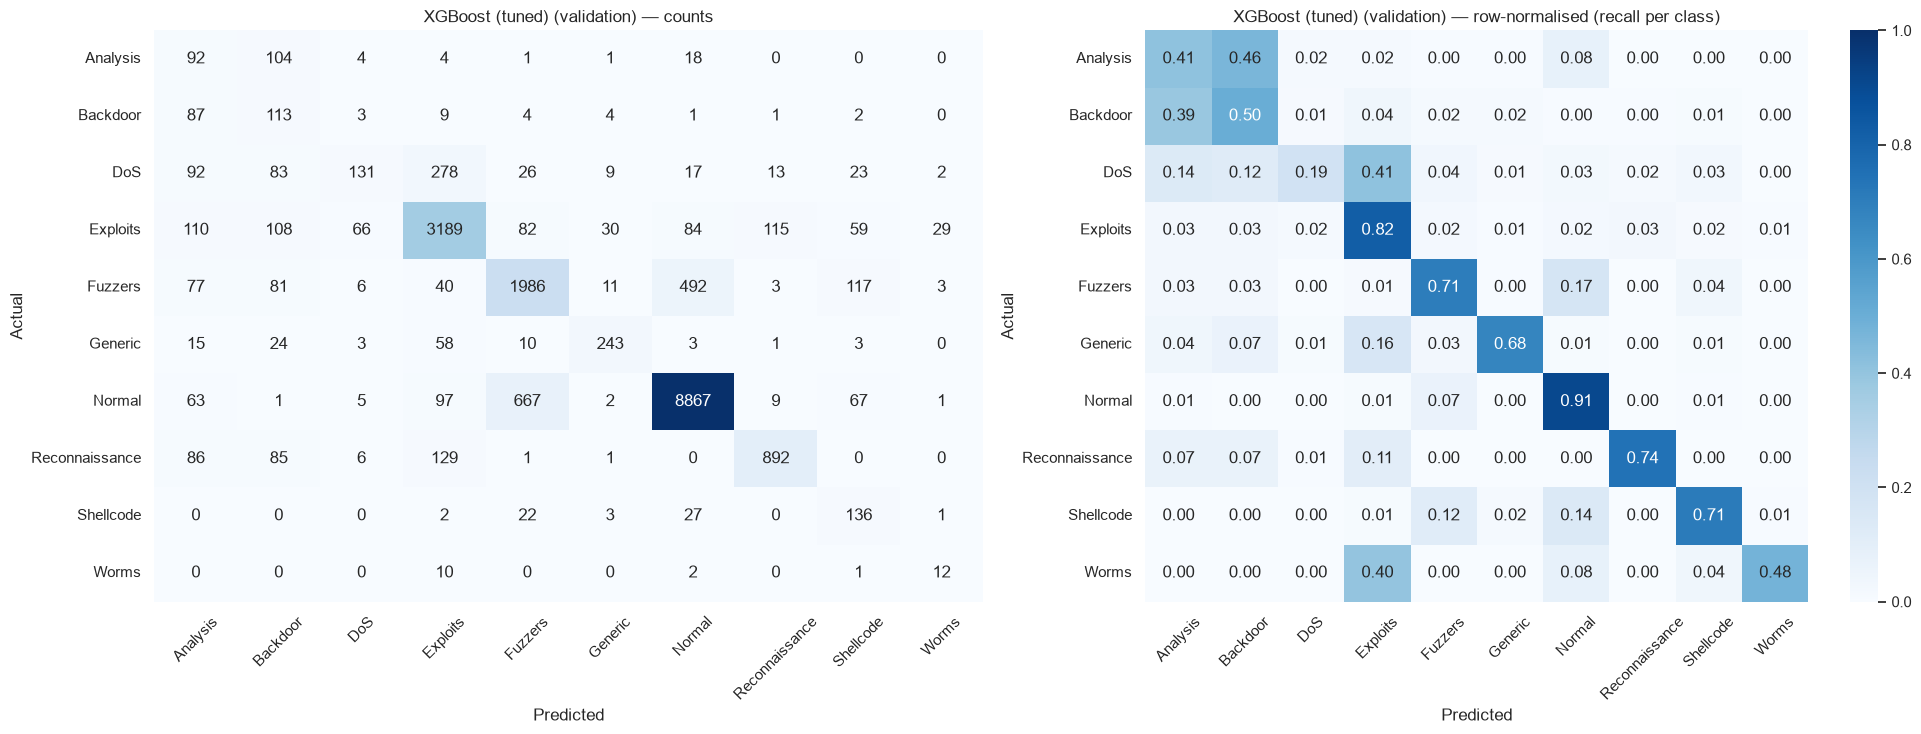

In [53]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, axes = plt.subplots(1, 2, figsize=(20, 7.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0], cbar=False)
    axes[0].set_title(f"{title} — counts")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title(f"{title} — row-normalised (recall per class)")
    for ax in axes:
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

plot_confusion(y_val_arr, y_val_pred, f"{leader_name} (validation)")

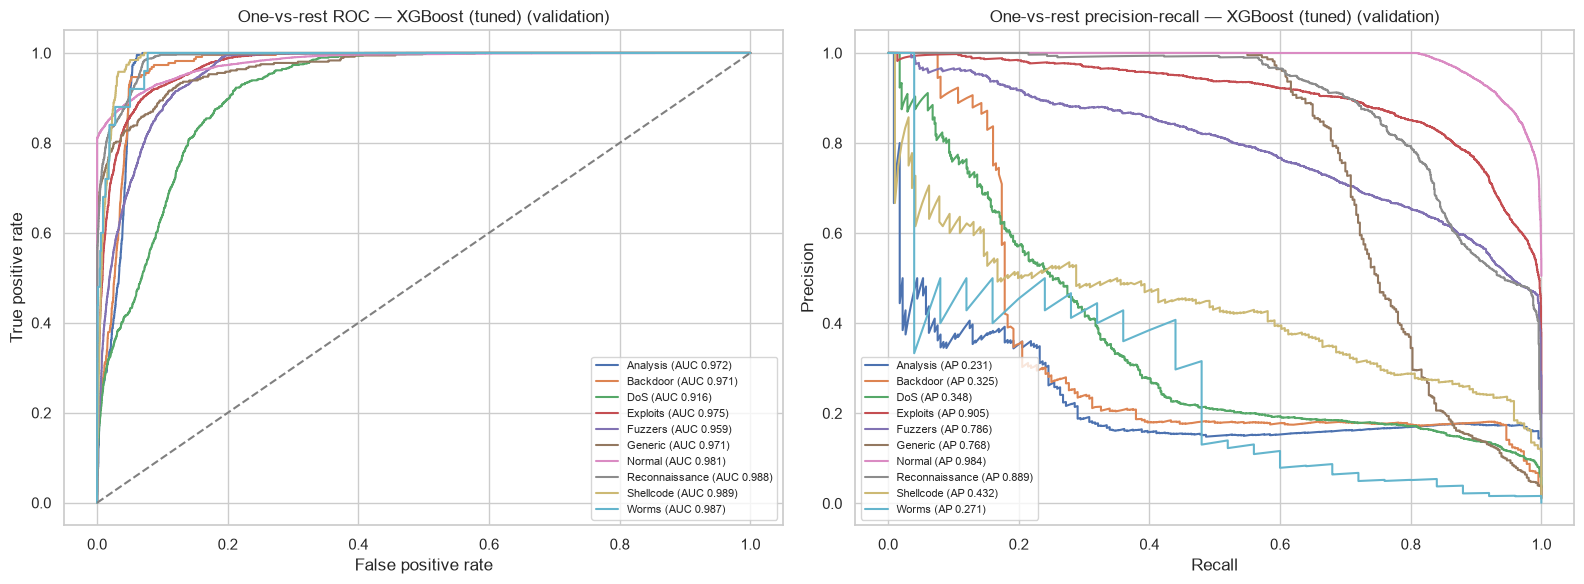

In [54]:
def plot_curves(y_true, proba, title):
    y_bin = label_binarize(y_true, classes=range(n_classes))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for k, name in enumerate(class_names):
        fpr_k, tpr_k, _ = roc_curve(y_bin[:, k], proba[:, k])
        axes[0].plot(fpr_k, tpr_k, label=f"{name} (AUC {roc_auc_score(y_bin[:, k], proba[:, k]):.3f})")
        p_k, r_k, _ = precision_recall_curve(y_bin[:, k], proba[:, k])
        axes[1].plot(r_k, p_k, label=f"{name} (AP {average_precision_score(y_bin[:, k], proba[:, k]):.3f})")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(title=f"One-vs-rest ROC — {title}", xlabel="False positive rate", ylabel="True positive rate")
    axes[1].set(title=f"One-vs-rest precision-recall — {title}", xlabel="Recall", ylabel="Precision")
    for ax in axes: ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
    plt.tight_layout(); plt.show()

plot_curves(y_val_arr, y_val_proba, f"{leader_name} (validation)")

## Step 20 — Final Evaluation on the UNSW-NB15 Test Set

All models are scored once on the official held-out test file. These numbers are **for reporting only** — the final model in Step 22 is chosen from the validation results,
so the test set is never used to make a decision.

The official test file is not just a random slice of the training file: its class mix is different (for example far more `Generic` flows),
so lower scores than on validation are expected and reflect distribution shift.

In [55]:
test_results = {name: evaluate_model(model, X_test_sel, y_test_arr) for name, model in fitted_models.items()}
test_df_results = pd.DataFrame(test_results).T
test_df_results.sort_values("f1_macro", ascending=False).round(4)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,pr_auc_macro,minority_f1,macro_fpr,normal_false_alarm_rate,attack_miss_rate
LightGBM,0.7443,0.4975,0.5884,0.4916,0.7716,0.9593,0.5197,0.3511,0.0289,0.2292,0.0364
XGBoost,0.7344,0.4885,0.6144,0.4799,0.7690,0.9578,0.5256,0.3308,0.0295,0.2489,0.0354
Random Forest,0.7327,0.4904,0.5725,0.4720,0.7680,0.9442,0.4897,0.3327,0.0298,0.2439,0.0378
XGBoost (tuned),0.7303,0.4832,0.6007,0.4658,0.7641,0.9580,0.5262,0.3185,0.0301,0.2472,0.0351
Decision Tree,0.7073,0.4523,0.5376,0.4439,0.7439,0.8144,0.3691,0.3159,0.0332,0.2631,0.0515
Random Forest (tuned),0.6989,0.4844,0.5490,0.4023,0.7426,0.9506,0.4663,0.2590,0.0329,0.2871,0.0308
Logistic Regression,0.6066,0.3590,0.4715,0.3217,0.6486,0.9004,0.3261,0.2232,0.0449,0.3819,0.0850


## Step 21 — Compare All Models

In [56]:
compare = pd.concat({"validation": val_df, "test": test_df_results}, axis=1)
compare[[("validation", "f1_macro"), ("test", "f1_macro"), ("validation", "recall_macro"), ("test", "recall_macro"),
         ("validation", "accuracy"), ("test", "accuracy")]].sort_values(("validation", "f1_macro"), ascending=False).round(4)

,validation,test,validation,test,validation,test
,f1_macro,f1_macro,recall_macro,recall_macro,accuracy,accuracy
XGBoost (tuned),0.5554,0.4658,0.6156,0.6007,0.8087,0.7303
XGBoost,0.5514,0.4799,0.6145,0.6144,0.8086,0.7344
LightGBM,0.5354,0.4916,0.5573,0.5884,0.8061,0.7443
Random Forest (tuned),0.5140,0.4023,0.5593,0.5490,0.7971,0.6989
Random Forest,0.5137,0.4720,0.5302,0.5725,0.7944,0.7327
Decision Tree,0.4805,0.4439,0.5031,0.5376,0.7654,0.7073
Logistic Regression,0.3998,0.3217,0.4710,0.4715,0.6754,0.6066


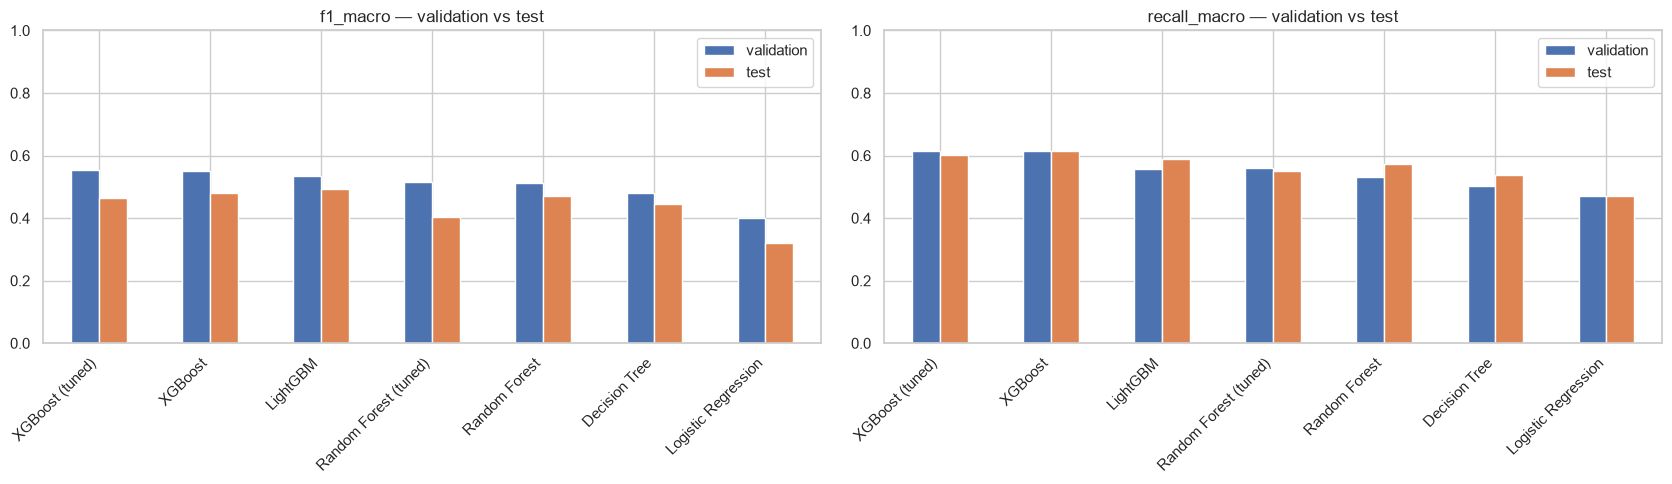

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
order = val_df.sort_values("f1_macro", ascending=False).index
for ax, metric in zip(axes, ["f1_macro", "recall_macro"]):
    pd.DataFrame({"validation": val_df.loc[order, metric], "test": test_df_results.loc[order, metric]}).plot(
        kind="bar", ax=ax, title=f"{metric} — validation vs test")
    ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels(): lbl.set_ha("right")
plt.tight_layout(); plt.show()

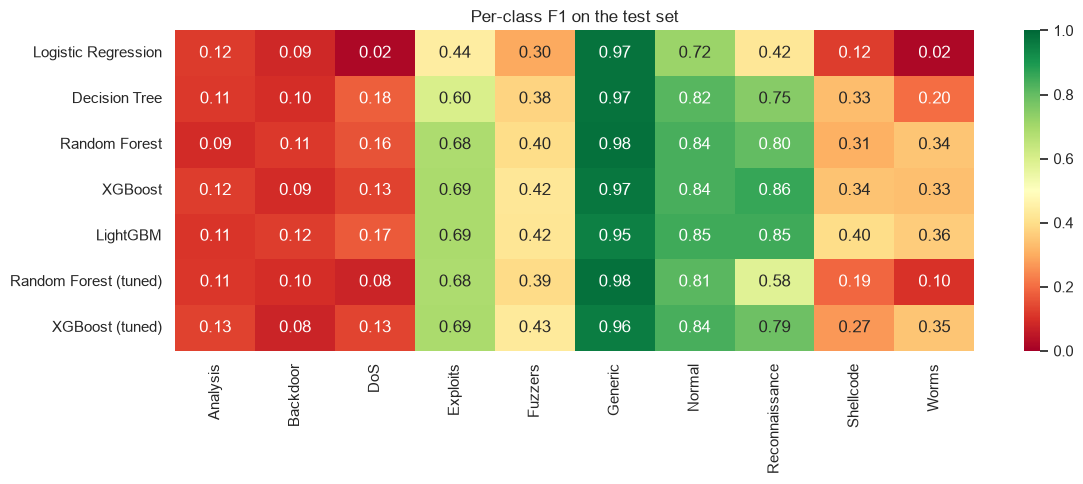

In [58]:
# Per-class F1 on the test set for every model: shows WHERE each model is strong or weak
per_class_f1 = pd.DataFrame(
    {name: f1_score(y_test_arr, m.predict(X_test_sel), average=None, labels=range(n_classes), zero_division=0)
     for name, m in fitted_models.items()}, index=class_names).T

plt.figure(figsize=(12, 5))
sns.heatmap(per_class_f1, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1)
plt.title("Per-class F1 on the test set"); plt.tight_layout(); plt.show()

## Step 22 — Select the Final Model

The model is picked from the **validation** results on four criteria that matter for intrusion detection, not on accuracy:

| Criterion | Column | Direction |
|---|---|---|
| Recall | `recall_macro` | higher is better |
| F1-score | `f1_macro` | higher is better |
| False-positive rate | `macro_fpr` | lower is better |
| Minority-class performance | `minority_f1` | higher is better |

Each model is ranked on every criterion; the model with the best **average rank** wins (ties are broken by macro-F1).
`normal_false_alarm_rate` and `attack_miss_rate` are shown next to it as operational sanity checks.

In [59]:
criteria = val_df[["recall_macro", "f1_macro", "macro_fpr", "minority_f1", "normal_false_alarm_rate", "attack_miss_rate"]]

ranks = pd.DataFrame({
    "recall_macro": criteria["recall_macro"].rank(ascending=False),
    "f1_macro": criteria["f1_macro"].rank(ascending=False),
    "minority_f1": criteria["minority_f1"].rank(ascending=False),
    "macro_fpr": criteria["macro_fpr"].rank(ascending=True),
})
selection_df = criteria.assign(avg_rank=ranks.mean(axis=1)).sort_values(["avg_rank", "f1_macro"], ascending=[True, False])
selection_df.round(4)

,recall_macro,f1_macro,macro_fpr,minority_f1,normal_false_alarm_rate,attack_miss_rate,avg_rank
XGBoost (tuned),0.6156,0.5554,0.0242,0.3831,0.0933,0.0672,1.00
XGBoost,0.6145,0.5514,0.0243,0.3772,0.0910,0.0690,2.00
LightGBM,0.5573,0.5354,0.0249,0.3551,0.0860,0.0746,3.25
Random Forest (tuned),0.5593,0.5140,0.0252,0.3230,0.1038,0.0578,4.00
Random Forest,0.5302,0.5137,0.0265,0.3345,0.0984,0.0747,4.75
Decision Tree,0.5031,0.4805,0.0301,0.2883,0.0995,0.0936,6.00
Logistic Regression,0.4710,0.3998,0.0422,0.2310,0.1692,0.1428,7.00


In [60]:
final_model_name = selection_df.index[0]
final_model = fitted_models[final_model_name]
print("Selected final model:", final_model_name)
print(selection_df.loc[final_model_name].round(4).to_string())

Selected final model: XGBoost (tuned)
recall_macro               0.6156
f1_macro                   0.5554
macro_fpr                  0.0242
minority_f1                0.3831
normal_false_alarm_rate    0.0933
attack_miss_rate           0.0672
avg_rank                   1.0000


=== XGBoost (tuned) — UNSW-NB15 official test set ===
                precision    recall  f1-score   support

      Analysis      0.074     0.614     0.131       677
      Backdoor      0.044     0.262     0.075       583
           DoS      0.367     0.082     0.134      4089
      Exploits      0.795     0.611     0.691     11132
       Fuzzers      0.343     0.574     0.430      6062
       Generic      0.941     0.973     0.956     18871
        Normal      0.946     0.753     0.838     37000
Reconnaissance      0.925     0.686     0.788      3496
     Shellcode      0.161     0.815     0.268       378
         Worms      0.237     0.636     0.346        44

      accuracy                          0.730     82332
     macro avg      0.483     0.601     0.466     82332
  weighted avg      0.833     0.730     0.764     82332



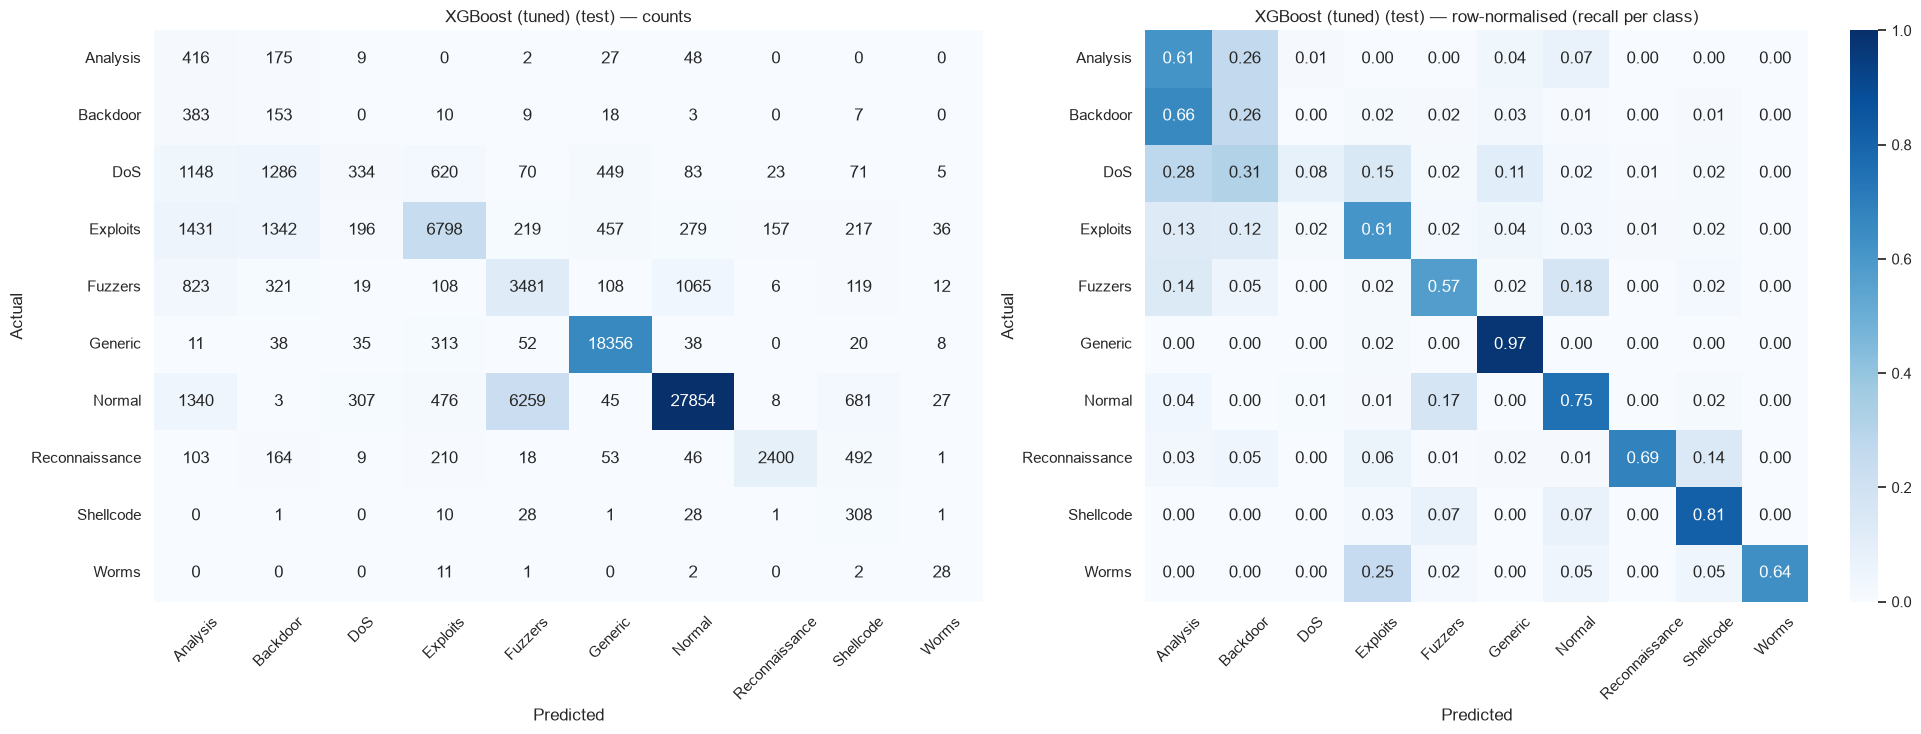

In [61]:
# Test-set behaviour of the selected model
y_test_pred = final_model.predict(X_test_sel)
y_test_proba = final_model.predict_proba(X_test_sel)

print(f"=== {final_model_name} — UNSW-NB15 official test set ===")
print(classification_report(y_test_arr, y_test_pred, target_names=class_names, zero_division=0, digits=3))
plot_confusion(y_test_arr, y_test_pred, f"{final_model_name} (test)")

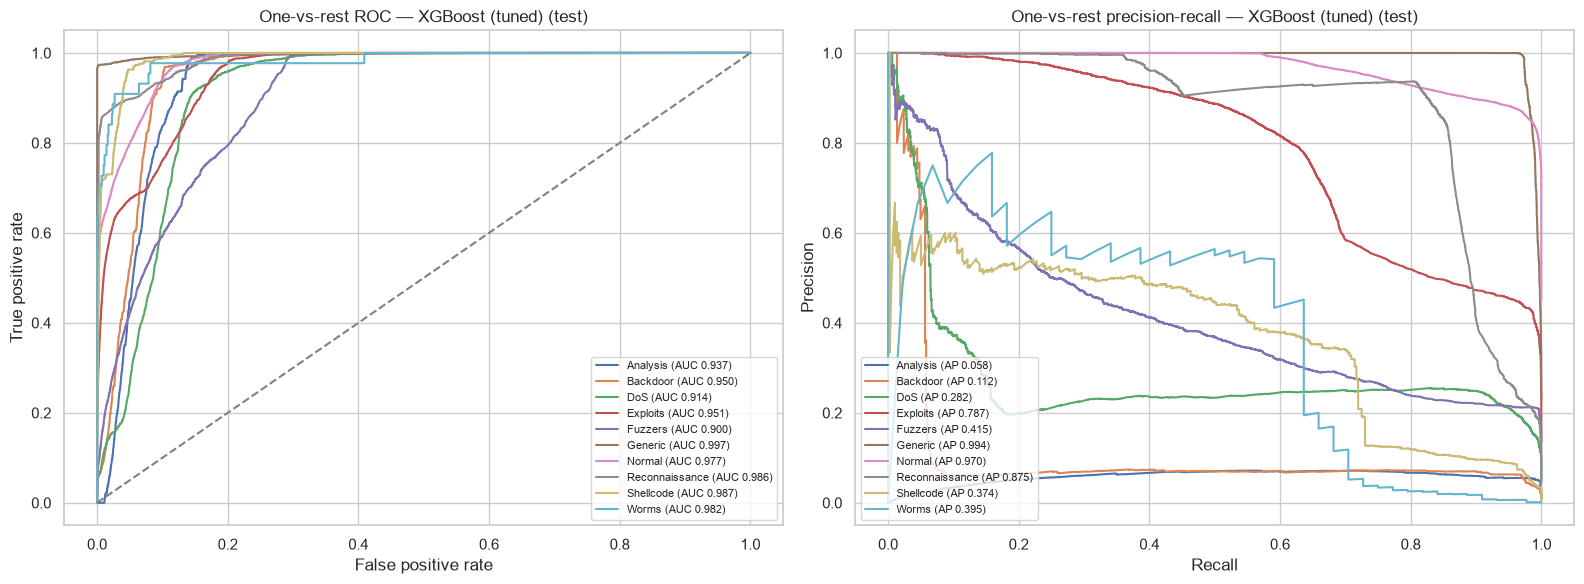

In [62]:
plot_curves(y_test_arr, y_test_proba, f"{final_model_name} (test)")

## Step 23 — Save the Final Model

Saved to `artifacts_unsw_multiclass/`:

| File | Content |
|---|---|
| `final_model_unsw_multiclass.joblib` | the selected classifier |
| `scaler_unsw_multiclass.joblib` | fitted `StandardScaler` |
| `label_encoder_unsw_multiclass.joblib` | `LabelEncoder` (class index ↔ attack name) |
| `preprocessing_unsw_multiclass.joblib` | everything needed to turn raw flows into model input: categorical/numeric columns, one-hot column list, selected-feature indices and names, training medians |
| `metadata_unsw_multiclass.json` | model name, classes, validation and test metrics |

In [63]:
ARTIFACT_DIR = Path("artifacts_unsw_multiclass")
ARTIFACT_DIR.mkdir(exist_ok=True)

preprocessing = {
    "drop_cols": drop_cols,
    "raw_feature_order": X.columns.tolist(),
    "categorical_cols": categorical_cols,
    "numerical_cols": numerical_cols,
    "ohe_columns": ohe_columns,
    "selected_idx": keep_idx,
    "selected_features": feature_columns_selected,
    "train_medians": train_medians.to_dict(),
    "class_names": class_names,
}

joblib.dump(final_model, ARTIFACT_DIR / "final_model_unsw_multiclass.joblib", compress=3)
joblib.dump(scaler, ARTIFACT_DIR / "scaler_unsw_multiclass.joblib")
joblib.dump(target_encoder, ARTIFACT_DIR / "label_encoder_unsw_multiclass.joblib")
joblib.dump(preprocessing, ARTIFACT_DIR / "preprocessing_unsw_multiclass.joblib")

metadata = {
    "final_model": final_model_name,
    "classes": class_names,
    "n_features_raw": len(X.columns),
    "n_features_encoded": len(ohe_columns),
    "n_features_selected": len(feature_columns_selected),
    "validation_metrics": {k: float(v) for k, v in val_results[final_model_name].items()},
    "test_metrics": {k: float(v) for k, v in test_results[final_model_name].items()},
}
(ARTIFACT_DIR / "metadata_unsw_multiclass.json").write_text(json.dumps(metadata, indent=2))

for f in sorted(ARTIFACT_DIR.iterdir()):
    print(f"{f.name:45s} {f.stat().st_size / 1e6:8.2f} MB")

final_model_unsw_multiclass.joblib                4.75 MB
label_encoder_unsw_multiclass.joblib              0.00 MB
metadata_unsw_multiclass.json                     0.00 MB
preprocessing_unsw_multiclass.joblib              0.01 MB
scaler_unsw_multiclass.joblib                     0.01 MB


In [64]:
# Reload from disk and check that raw traffic -> prediction reproduces the in-memory results exactly
def predict_attack_category(raw_df, artifact_dir=ARTIFACT_DIR):
    model = joblib.load(artifact_dir / "final_model_unsw_multiclass.joblib")
    scaler_ = joblib.load(artifact_dir / "scaler_unsw_multiclass.joblib")
    enc = joblib.load(artifact_dir / "label_encoder_unsw_multiclass.joblib")
    pp = joblib.load(artifact_dir / "preprocessing_unsw_multiclass.joblib")

    df = raw_df.drop(columns=[c for c in pp["drop_cols"] if c in raw_df.columns])[pp["raw_feature_order"]].copy()
    for c in pp["categorical_cols"]:
        df[c] = df[c].astype(str).str.strip()
    df[pp["numerical_cols"]] = (df[pp["numerical_cols"]].replace([np.inf, -np.inf], np.nan)
                                .fillna(pd.Series(pp["train_medians"])))
    df = pd.get_dummies(df, columns=pp["categorical_cols"], dtype=float).reindex(columns=pp["ohe_columns"], fill_value=0.0)

    X_new = scaler_.transform(df)[:, pp["selected_idx"]]
    proba = model.predict_proba(X_new)
    return pd.DataFrame({"predicted_category": enc.inverse_transform(proba.argmax(axis=1)),
                         "confidence": proba.max(axis=1)}, index=raw_df.index)

demo = predict_attack_category(test_df.head(2000))
in_memory = target_encoder.inverse_transform(final_model.predict(X_test_sel[:2000]))
print("Reloaded pipeline matches in-memory predictions:", bool((demo["predicted_category"].to_numpy() == in_memory).all()))
pd.concat([test_df[TARGET_COL].head(8).rename("actual"), demo.head(8)], axis=1)

Reloaded pipeline matches in-memory predictions: True


,actual,predicted_category,confidence
0,Normal,Shellcode,0.764036
1,Normal,Fuzzers,0.478802
2,Normal,Fuzzers,0.361433
3,Normal,Fuzzers,0.534804
4,Normal,Fuzzers,0.611066
5,Normal,Fuzzers,0.581482
6,Normal,Fuzzers,0.636185
7,Normal,Generic,0.488498


## Step 24 — Final Results & Conclusion

In [65]:
print("=== FINAL SUMMARY ===")
print(f"Final model : {final_model_name}")
print(f"Classes     : {n_classes} ({', '.join(class_names)})")
print(f"Features    : {len(feature_columns_selected)} of {len(feature_columns)} encoded features kept\n")

summary = pd.DataFrame({"validation": val_results[final_model_name], "test": test_results[final_model_name]}).round(4)
print(summary.to_string())

=== FINAL SUMMARY ===
Final model : XGBoost (tuned)
Classes     : 10 (Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Normal, Reconnaissance, Shellcode, Worms)
Features    : 176 of 186 encoded features kept

                         validation    test
accuracy                     0.8087  0.7303
precision_macro              0.5644  0.4832
recall_macro                 0.6156  0.6007
f1_macro                     0.5554  0.4658
f1_weighted                  0.8168  0.7641
roc_auc_ovr                  0.9708  0.9580
pr_auc_macro                 0.5940  0.5262
minority_f1                  0.3831  0.3185
macro_fpr                    0.0242  0.0301
normal_false_alarm_rate      0.0933  0.2472
attack_miss_rate             0.0672  0.0351


In [66]:
# Where does the final model struggle? Per-class recall/precision/F1 on the test set, weakest first
report = pd.DataFrame(classification_report(y_test_arr, y_test_pred, target_names=class_names,
                                            output_dict=True, zero_division=0)).T.loc[class_names]
report.sort_values("f1-score").round(3)

,precision,recall,f1-score,support
Backdoor,0.044,0.262,0.075,583.0
Analysis,0.074,0.614,0.131,677.0
DoS,0.367,0.082,0.134,4089.0
Shellcode,0.161,0.815,0.268,378.0
Worms,0.237,0.636,0.346,44.0
Fuzzers,0.343,0.574,0.430,6062.0
Exploits,0.795,0.611,0.691,11132.0
Reconnaissance,0.925,0.686,0.788,3496.0
Normal,0.946,0.753,0.838,37000.0
Generic,0.941,0.973,0.956,18871.0


### Conclusion

**What was done.** The binary notebook was converted to a 10-class problem (Normal + 9 attack categories). The same eight model variants were compared —
Logistic Regression, Decision Tree, Random Forest, XGBoost, LightGBM, and tuned Random Forest / XGBoost — after one-hot encoding, standardisation, capped SMOTE on the training split only,
and correlation/importance-based feature pruning. The final model was chosen from **validation** results by average rank over macro-recall, macro-F1, macro false-positive rate and minority-class F1, not by accuracy.

**How to read the results.**
- Compare macro-F1 with accuracy. A large gap means the model is good on big classes (`Normal`, `Exploits`, `Fuzzers`) and weak on small ones.
- The per-class F1 heatmap (Step 21) and the report above show which classes are hard. In UNSW-NB15 the usual trouble spots are `Analysis`, `Backdoor` and `DoS`
  (their traffic overlaps heavily with `Exploits`/`Normal`) and `Worms` (only ~100 training rows even before splitting).
- Test scores are expected to be lower than validation scores: the official test file has a different class mix from the training file, so validation is a
  random slice of the training distribution while test measures generalisation under shift.

**Caveats.**
- Removing duplicates (Step 4.2) shrinks the training set a lot and changes its class balance — most of all for `Generic`. That makes validation scores more honest, but numbers are not directly comparable with papers that keep duplicates.
- SMOTE interpolates between one-hot columns, so some synthetic rows have fractional dummy values; it works well in practice for tree models, but `SMOTENC` is the stricter alternative if that matters.
- Hyper-parameters were searched on a subsample with small grids to keep runtime reasonable; widen `rf_param_dist` / `xgb_param_grid` and raise `TUNE_N` for a final production run.
- SHAP was computed on 300 validation flows with the tuned Random Forest; raise `SHAP_SAMPLE` for smoother global plots.

**Reproducing predictions.** `predict_attack_category(raw_df)` (Step 23) loads the saved model, scaler, label encoder and preprocessing bundle and returns the predicted category and confidence for raw UNSW-NB15-formatted flows.